# **Library**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Read data**

In [3]:
import pandas as pd
path_data="/content/drive/MyDrive/pairs stations(New).xlsx"
data_main=pd.read_excel(path_data)
data_main

,date_time (month/day/year/hour/minute),Activity,EBCN/ECBD,ECNE/ECPN,ECZM/EMCN,EMFS/EMPL,EMPL/EPLC,ESLN/ESPC,EBCN/ECNE
0,2011-01-01 00:00:00,0,5.504098,1.327685,0.447181,1.937412,0.236917,1.119214,0.835803
1,2011-01-01 00:10:00,0,5.877375,1.315512,0.462690,2.015547,0.210884,1.115207,0.785281
2,2011-01-01 00:20:00,0,6.153960,1.332526,0.479071,1.766882,0.231012,1.167966,0.786350
3,2011-01-01 00:30:00,0,6.136645,1.331539,0.463946,2.007342,0.218845,1.031693,0.755097
4,2011-01-01 00:40:00,0,6.236501,1.313023,0.495740,1.958200,0.234923,1.015917,0.805580
...,...,...,...,...,...,...,...,...,...
262939,2015-12-31 23:10:00,0,0.003808,0.421349,0.557343,1.850530,0.326409,1.165753,0.000596
262940,2015-12-31 23:20:00,0,0.003385,0.431831,0.561156,1.792946,0.326922,1.192454,0.000572
262941,2015-12-31 23:30:00,0,0.003528,0.402821,0.529258,1.860522,0.323025,1.112529,0.000582
262942,2015-12-31 23:40:00,0,0.003532,0.441584,0.573416,1.730714,0.351090,1.126961,0.000654


In [4]:
data_main_lim=data_main.copy()
data_main_lim.index=data_main["date_time (month/day/year/hour/minute)"]
data_main_lim=data_main_lim.drop("date_time (month/day/year/hour/minute)",axis=1)
for idx, item in enumerate(data_main_lim.columns):
  print(idx)
  data_col=data_main_lim[item]
  data_col[data_col>100]=100
  data_main_lim[item]=data_col


  # print(item)
 #data_main.loc[data_main>500]

0
1
2
3
4
5
6
7


<ipython-input-4-d72d566b8180>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_col[data_col>100]=100


array([<matplotlib.axes._subplots.AxesSubplot object at 0x7fc8cafdfee0>,
      dtype=object)

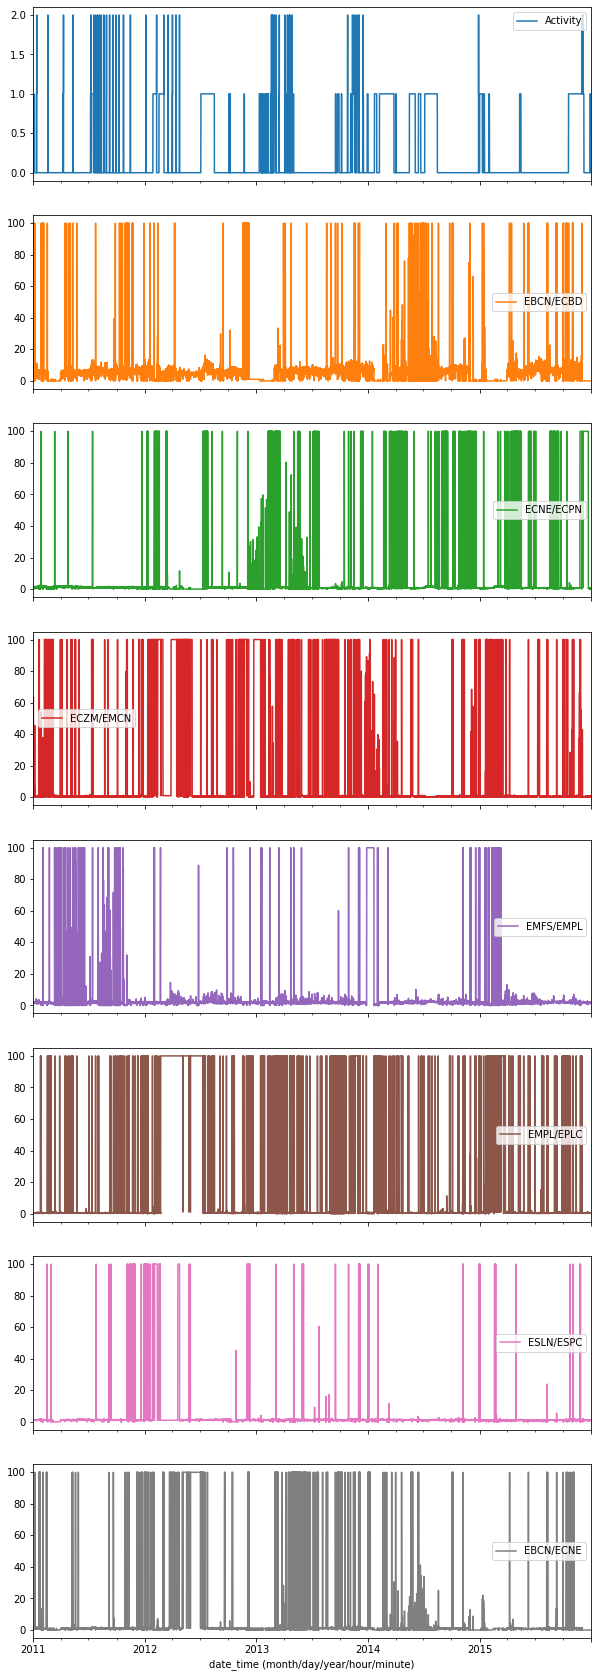

In [5]:
data_main_lim.plot(subplots=True, figsize=(10,30))

In [6]:
data_main_lim.isna().sum()

Activity     0
EBCN/ECBD    0
ECNE/ECPN    0
ECZM/EMCN    0
EMFS/EMPL    0
EMPL/EPLC    0
ESLN/ESPC    0
EBCN/ECNE    0
dtype: int64

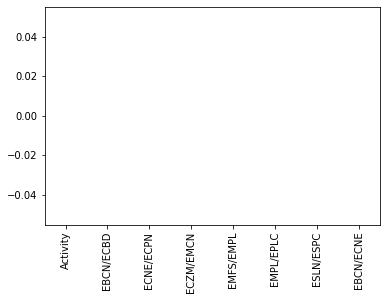

In [7]:
data_main_lim.isna().sum().plot(kind="bar")

# **preprocessing**

In [8]:
data_preprocessing=data_main_lim.copy()

In [9]:
# fill nan columns base int64 , float64 according mean columns 
# fill nan columns bas string and text by most frequency(mode)
number_columns=data_preprocessing.select_dtypes(["int64","float64"])
string_columns=data_preprocessing.select_dtypes(["object"])
for col_name in data_preprocessing.columns:
  if col_name in number_columns:
    # fill int or float missing value by mean
    data_preprocessing[col_name]=data_preprocessing[col_name].fillna(data_preprocessing[col_name].mean())
  else:
    # fill string and text by most frequency
    data_preprocessing[col_name]=data_preprocessing[col_name].fillna(data_preprocessing[col_name].mode()[0])
data_preprocessing.isna().sum()

Activity     0
EBCN/ECBD    0
ECNE/ECPN    0
ECZM/EMCN    0
EMFS/EMPL    0
EMPL/EPLC    0
ESLN/ESPC    0
EBCN/ECNE    0
dtype: int64

In [10]:
data_preprocessing.dtypes

Activity       int64
EBCN/ECBD    float64
ECNE/ECPN    float64
ECZM/EMCN    float64
EMFS/EMPL    float64
EMPL/EPLC    float64
ESLN/ESPC    float64
EBCN/ECNE    float64
dtype: object

In [11]:
data_ready=data_preprocessing.copy()
# data_ready=data_ready.drop(data_ready.columns[0],axis=1)

# **Visualization**

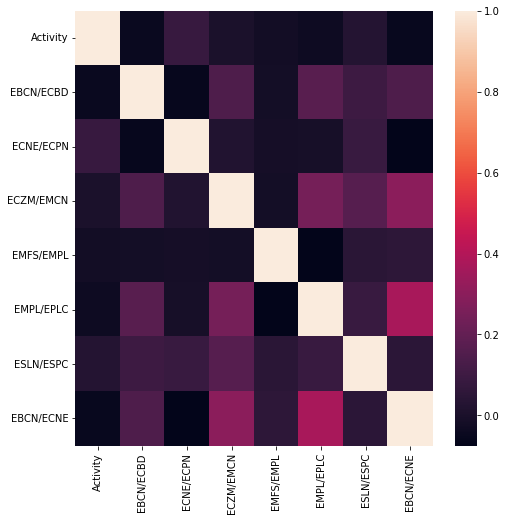

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8,8))
#plt.savefig("correlation1.png",dpi=300)
#plt.figure(figsize=(8,8))
sns.heatmap(data_ready.corr())

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

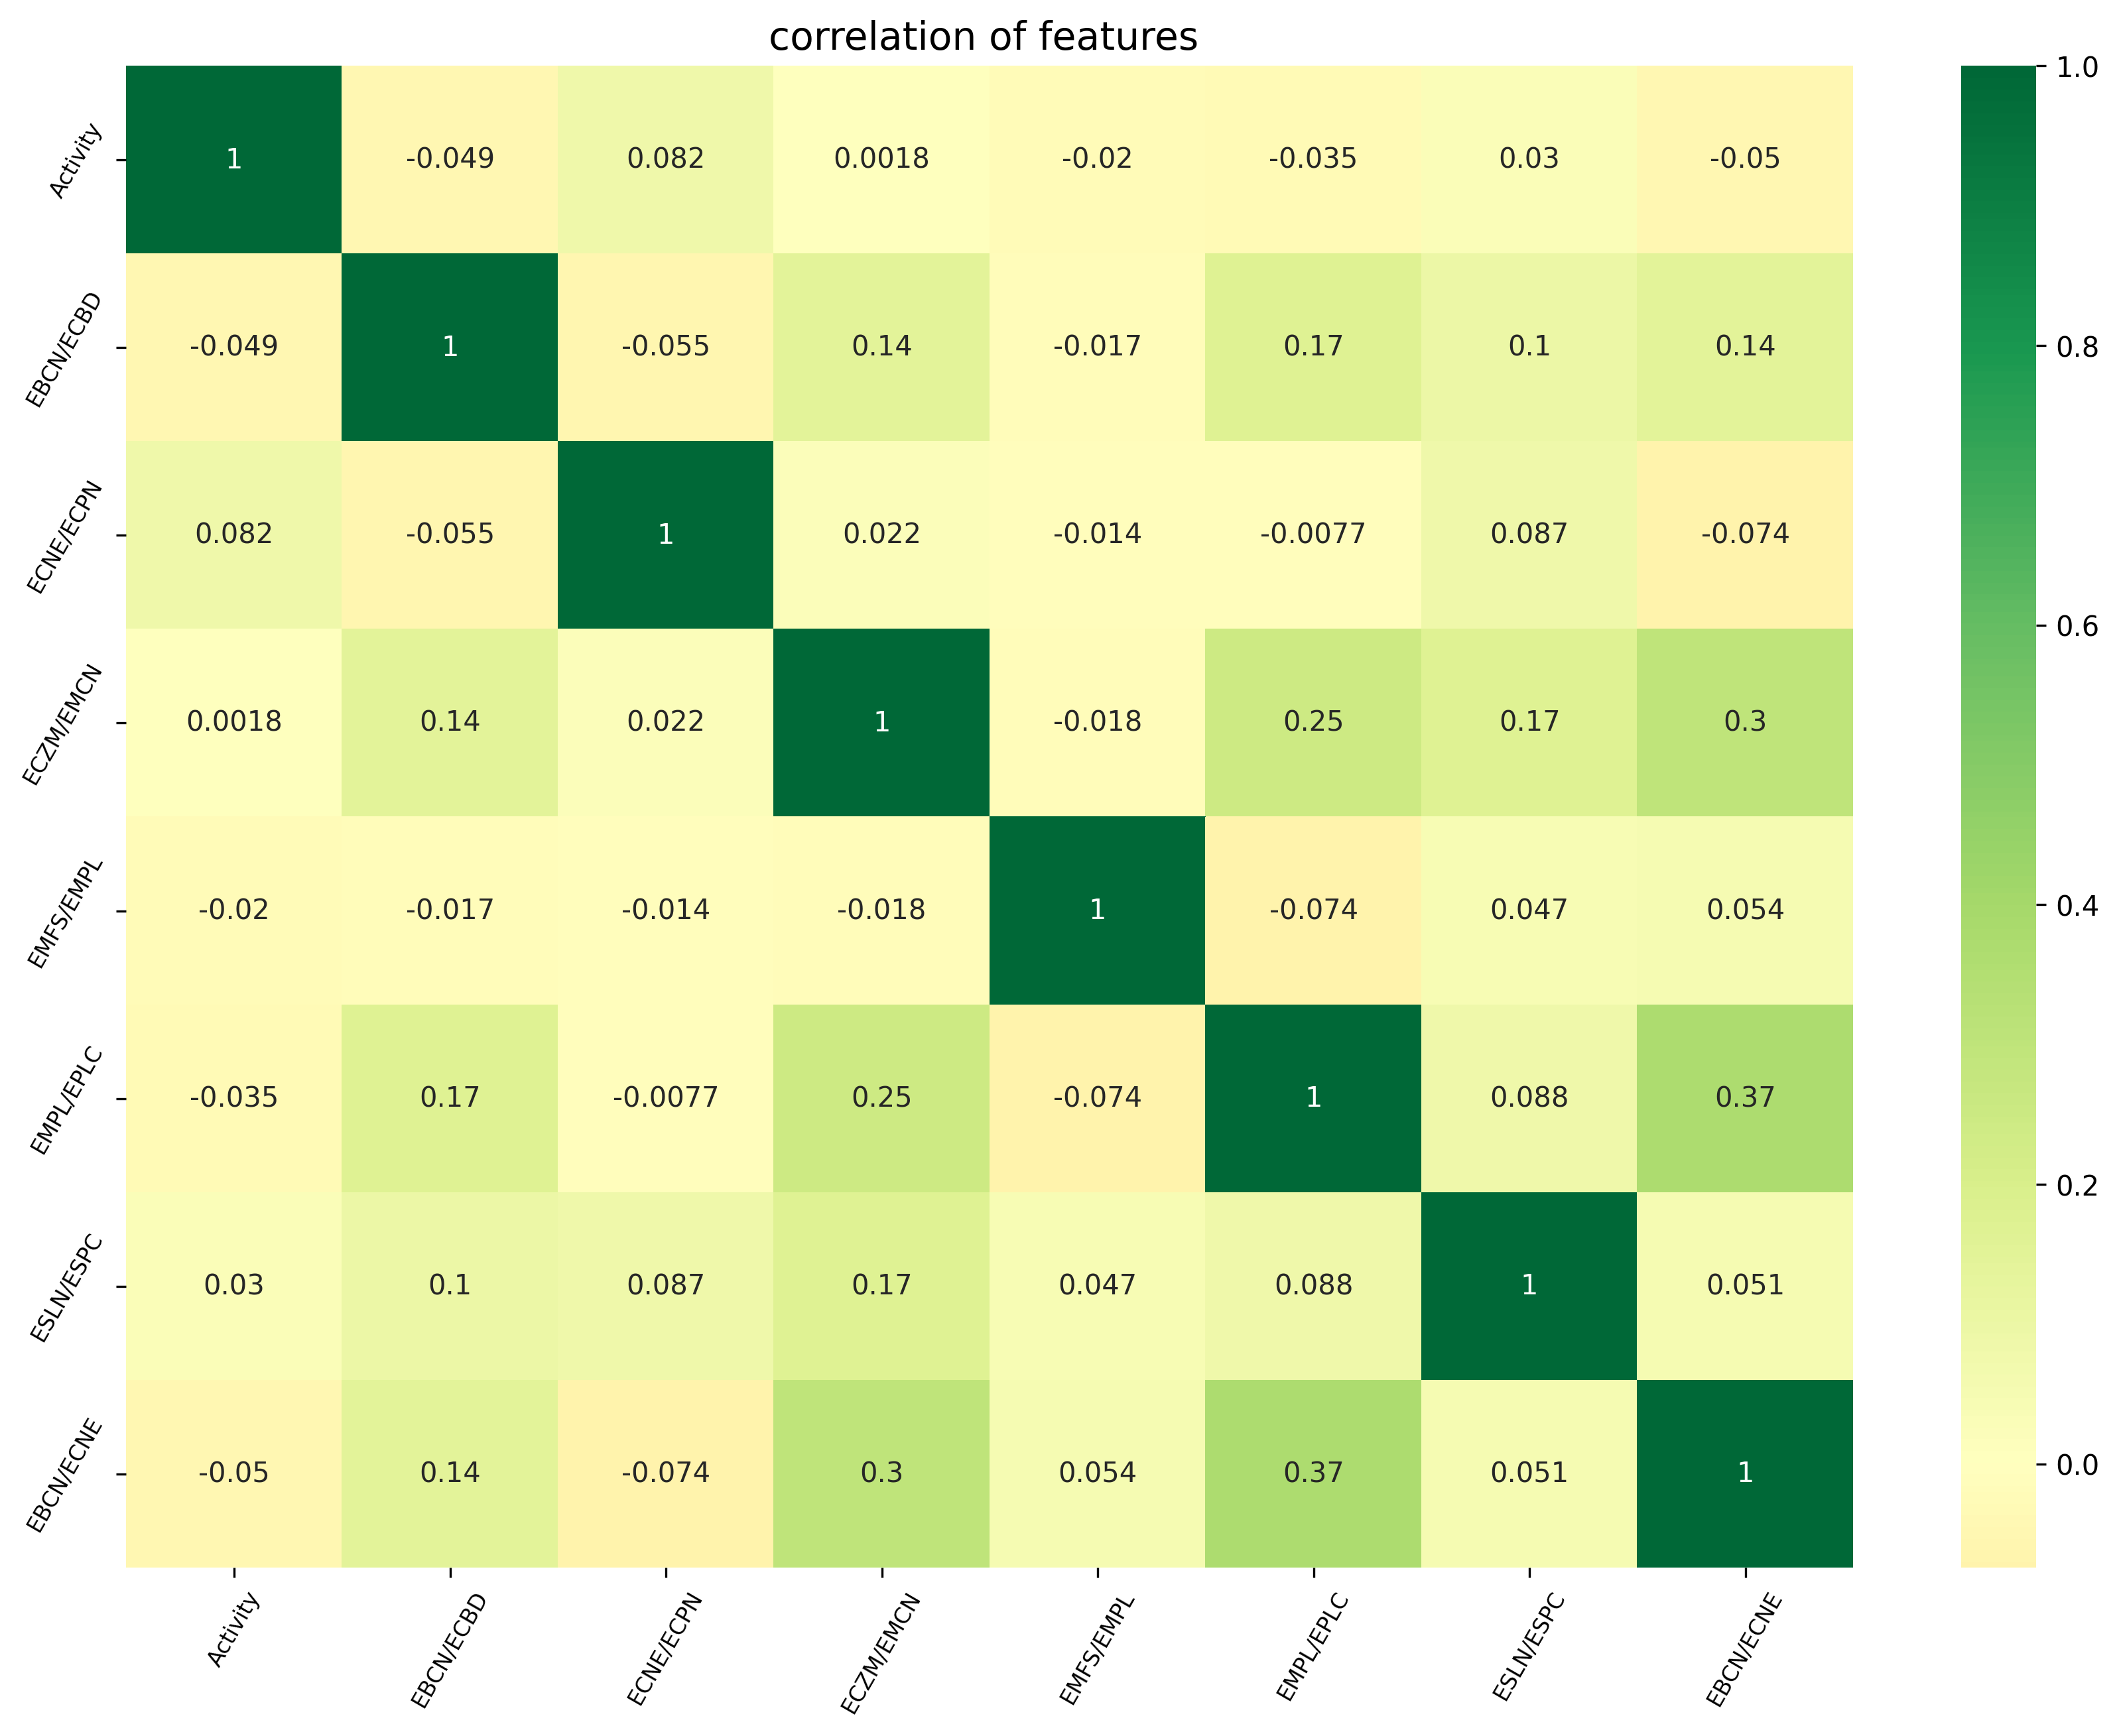

In [14]:
data_reedy_plot=data_ready.loc[:,data_ready.columns]
plt.figure(figsize=(14,10), dpi= 300)
sns.heatmap(round(data_reedy_plot.corr(),4), 
            xticklabels=data_reedy_plot.corr().columns,
            yticklabels=data_reedy_plot.corr().columns,
            cmap='RdYlGn', center=0, annot=True)

# Decorations
plt.title('correlation of features ', fontsize=14)
plt.xticks(fontsize=8,rotation=60)
plt.yticks(fontsize=8,rotation=60)
plt.savefig("correlation2.png",dpi=300)
plt.show()


In [15]:
data_reedy_plot.index=data_main["date_time (month/day/year/hour/minute)"]

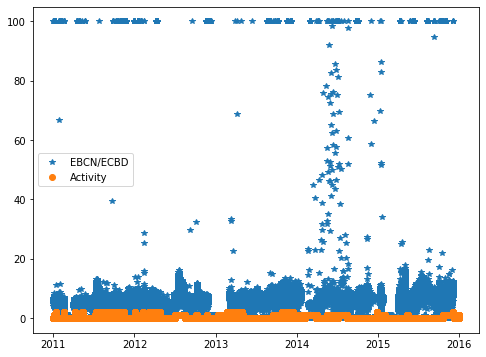

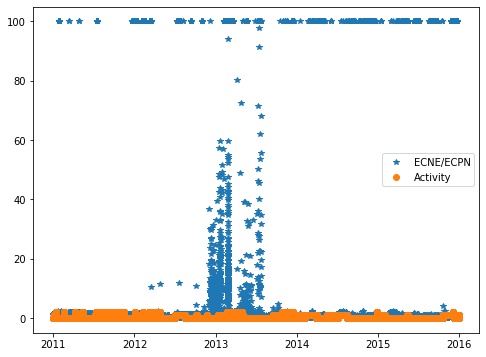

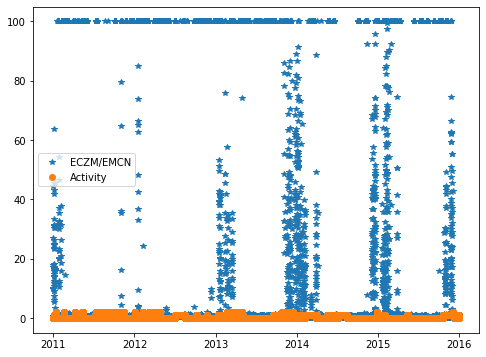

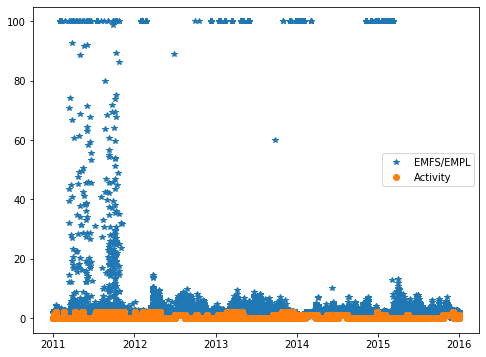

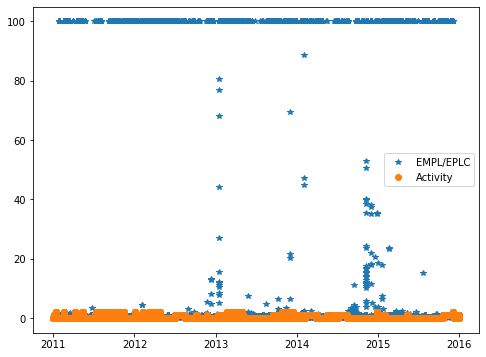

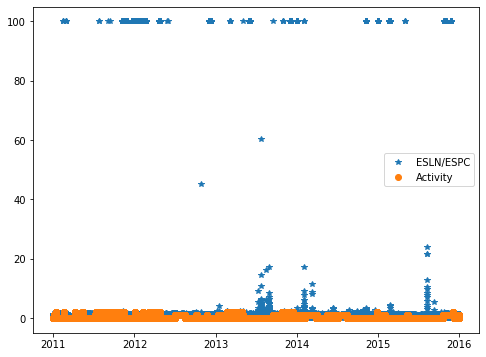

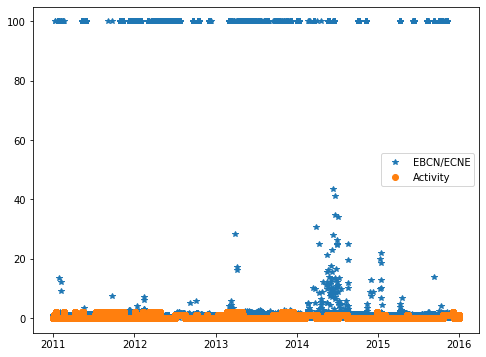

In [17]:
for item in data_reedy_plot.columns[1:]:
  plt.figure(figsize=(8,6))
  plt.plot(data_reedy_plot[item],'*')
  plt.plot(data_reedy_plot['Activity'],'o')
  plt.legend([item,'Activity'])

  plt.show()

In [18]:
from sklearn.preprocessing import Normalizer, MinMaxScaler
import matplotlib.pyplot as plt
sc =MinMaxScaler(feature_range=(0,10))
data_reedy_normal=data_reedy_plot.copy()
for item in data_reedy_plot.columns[1:]:
  # fit and transform
  data_reedy_normal[item] = sc.fit_transform(data_ready[item].values.reshape(-1,1))


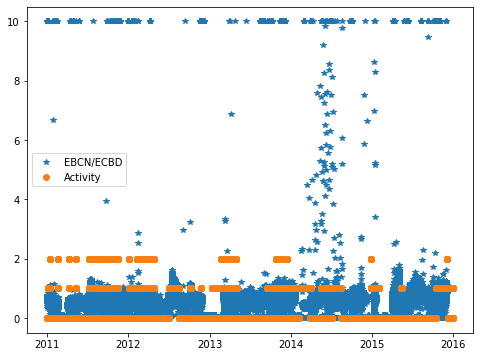

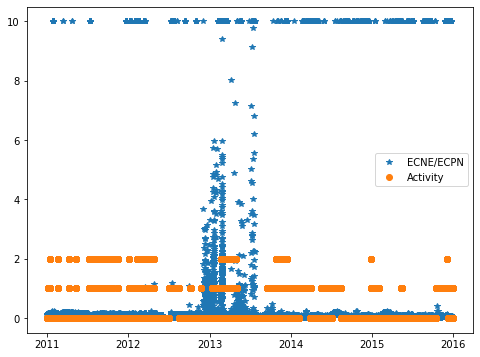

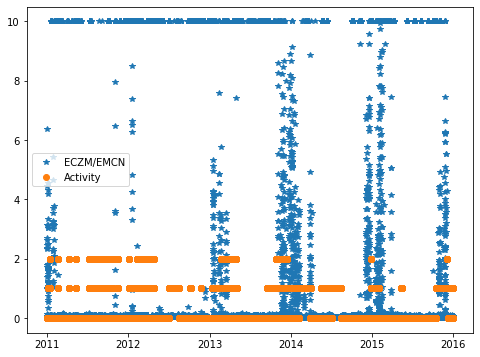

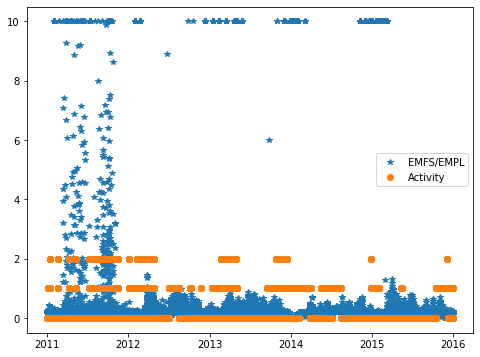

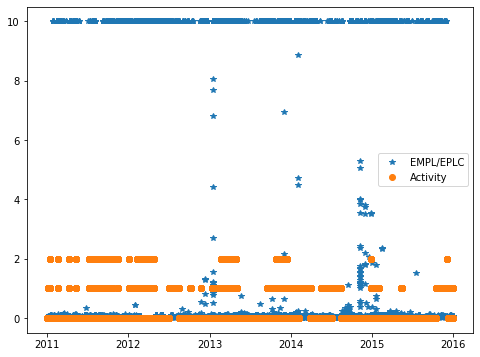

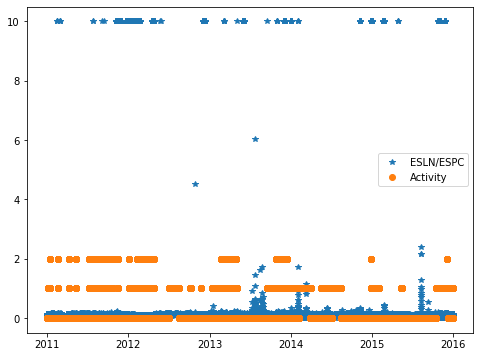

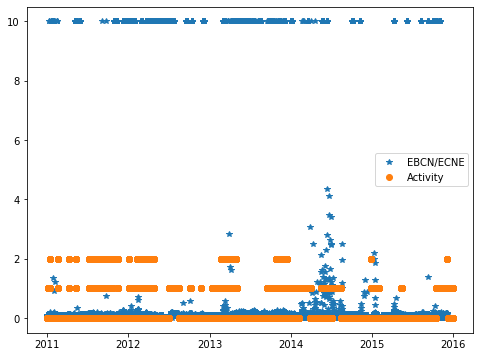

In [19]:
for item in data_reedy_normal.columns[1:]:
  plt.figure(figsize=(8,6))
  plt.plot(data_reedy_normal[item],'*')
  plt.plot(data_reedy_normal['Activity'],'o')
  plt.legend([item,'Activity'])
  plt.show()

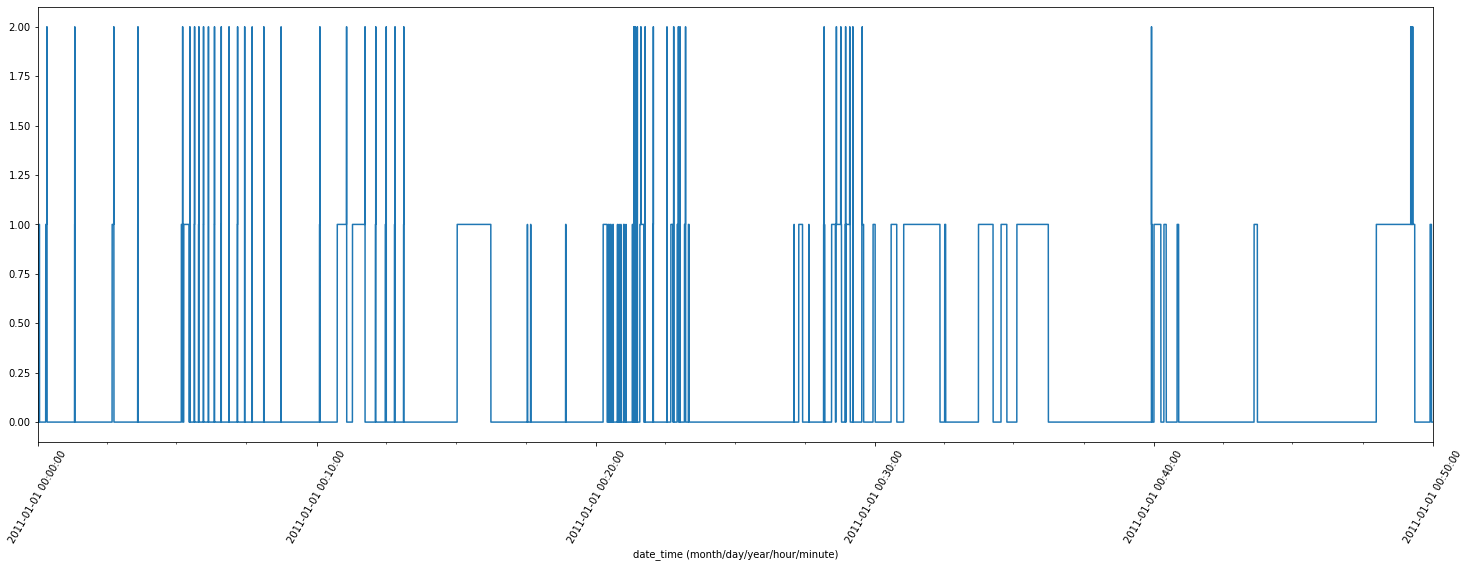

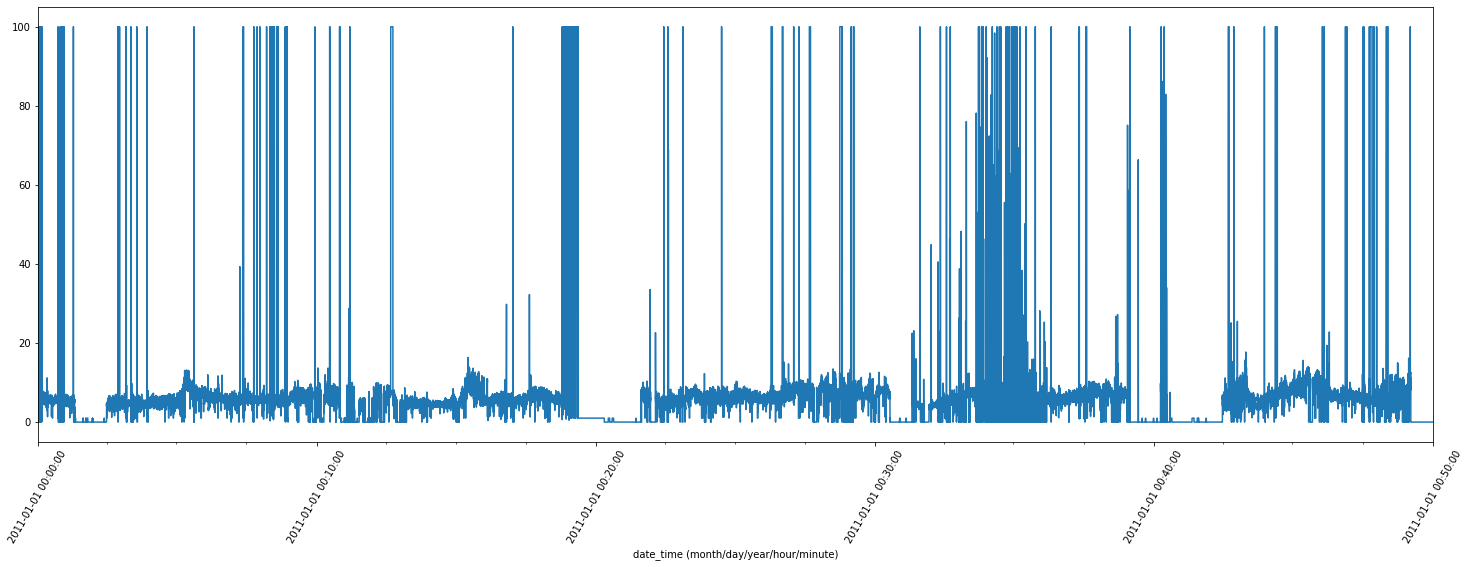

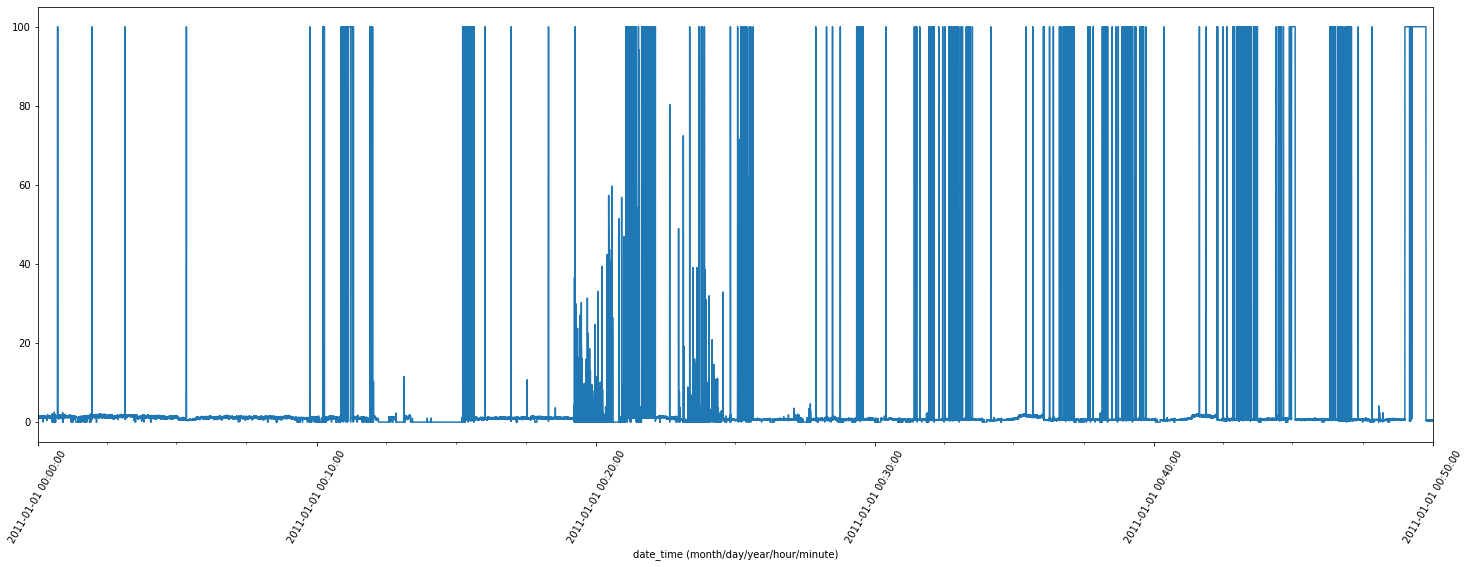

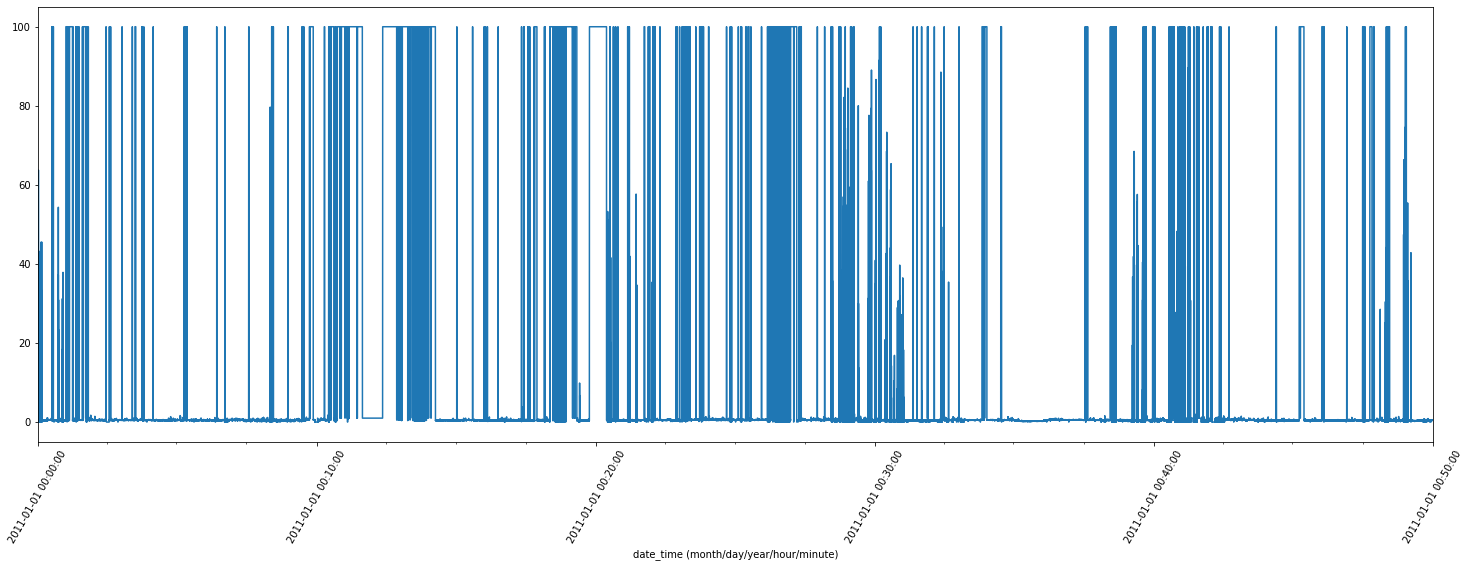

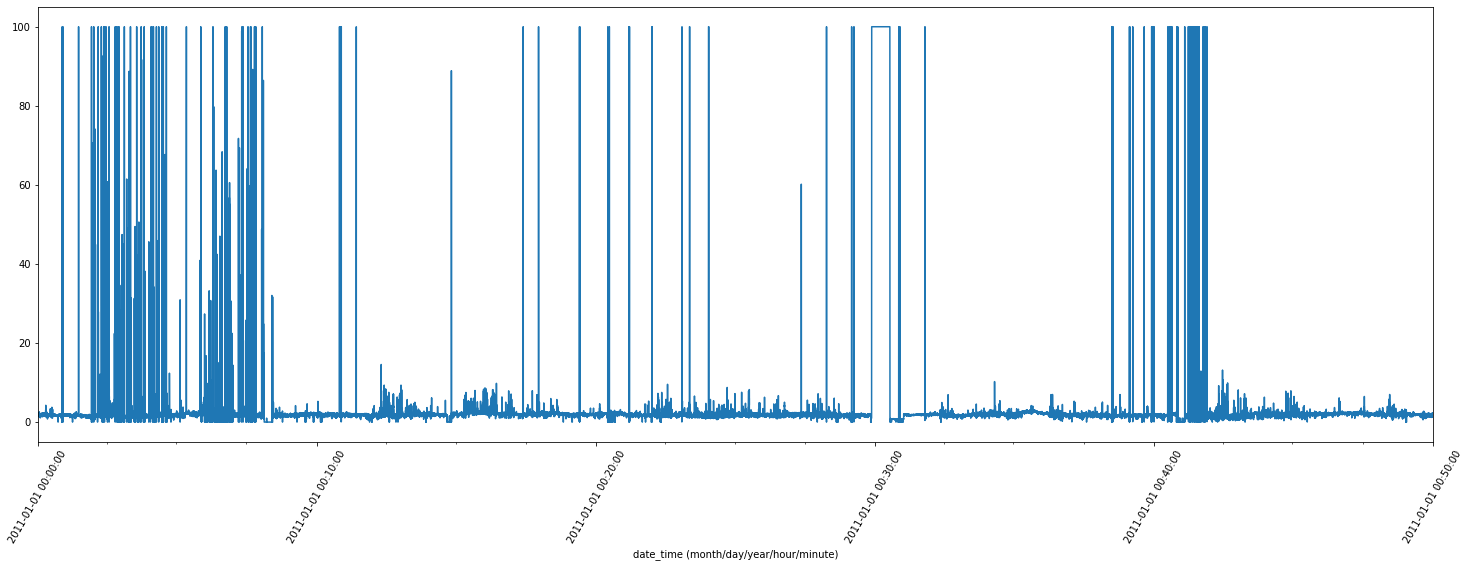

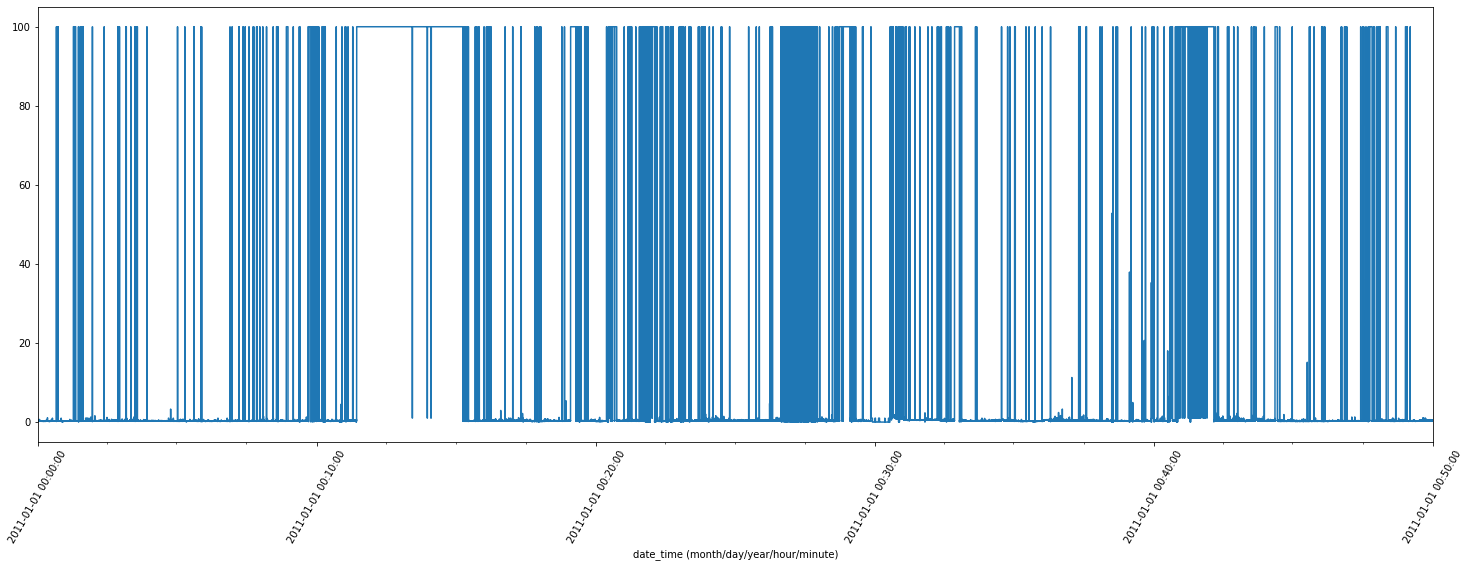

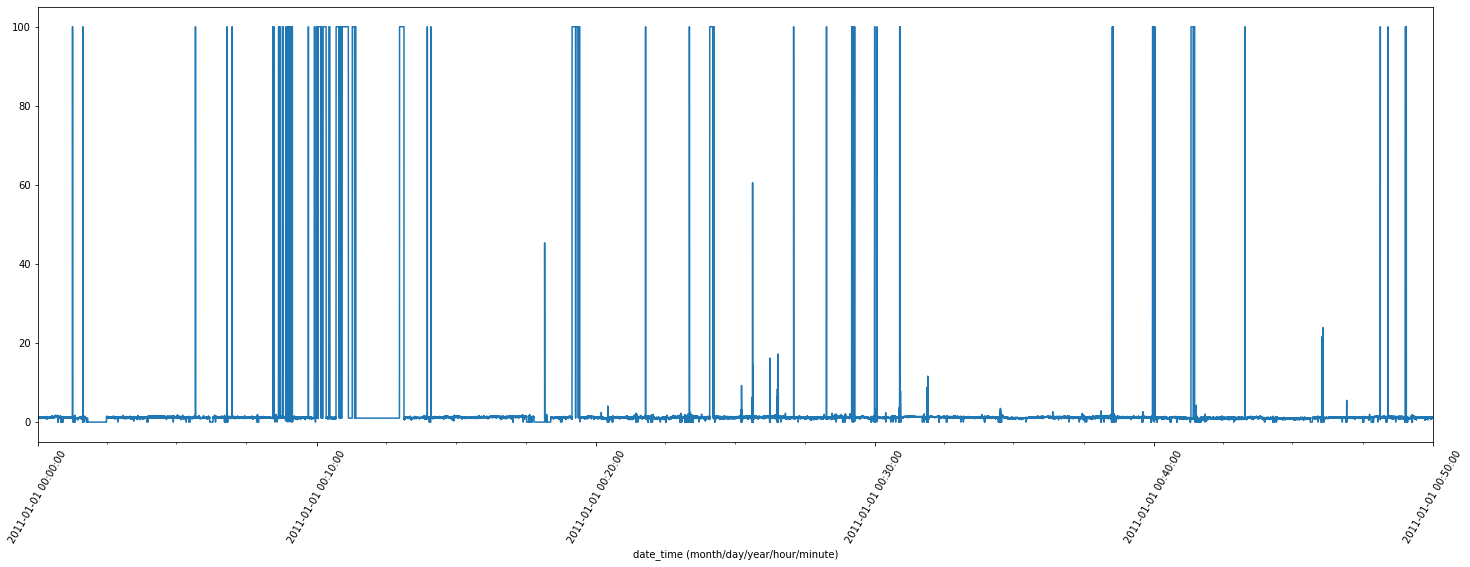

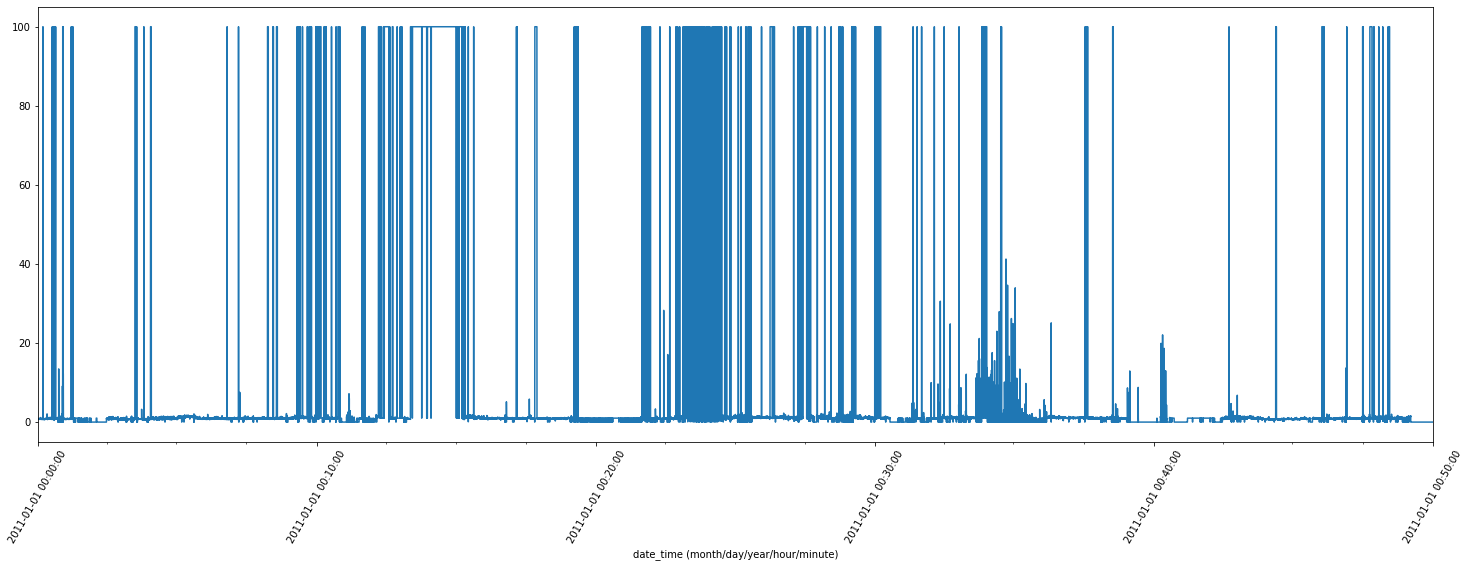

In [21]:
from IPython.core.pylabtools import figsize
for item in data_reedy_plot.columns:
  ax=data_reedy_plot[item].plot( figsize=(25,8),use_index=True)

  ax.set_xticklabels(data_reedy_plot.index,rotation=60)
  # ax.xticks(rotation=60)
 # plt.savefig("im_"+str(item.replace("/","_"))+".png",dpi=300)
  plt.show()

In [ ]:
# plt.plot(data_ready["Activity"],"o")
# plt.xticks(data_reedy_plot.index)
# plt.savefig("im2.png",dpi=300)
# plt.show()

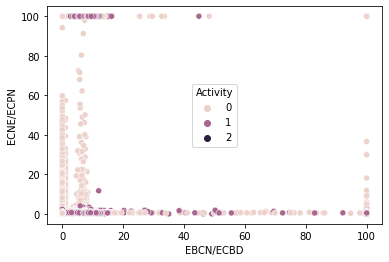

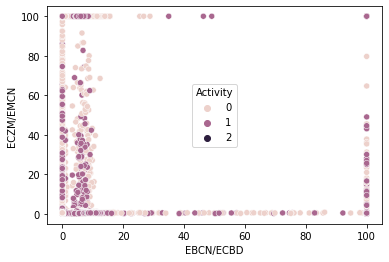

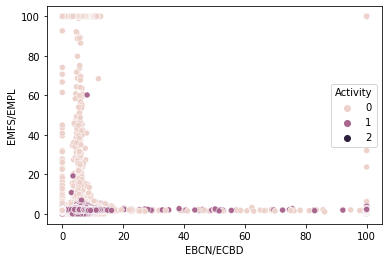

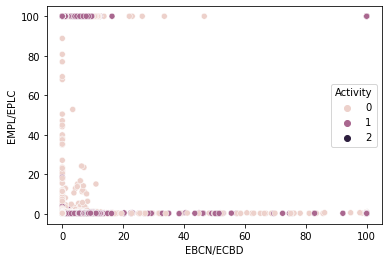

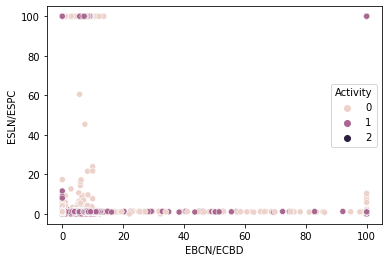

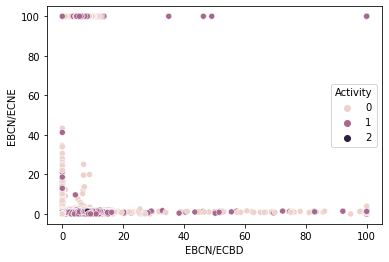

In [22]:
import matplotlib.pyplot as plt
col_names=data_ready.columns
for i in range(2,len(col_names)):
  plt.figure()
  sns.scatterplot(data=data_ready,
                  x=col_names[1],
                  y=col_names[i],
                  hue=col_names[0])
 # plt.savefig("im_scatter"+str(i)+".png",dpi=300)

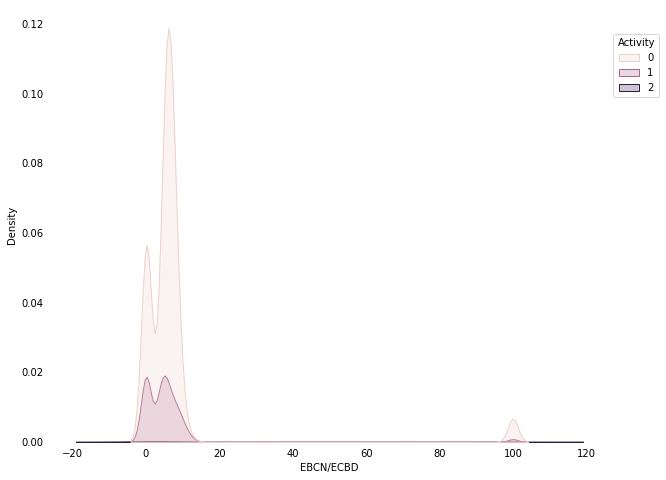

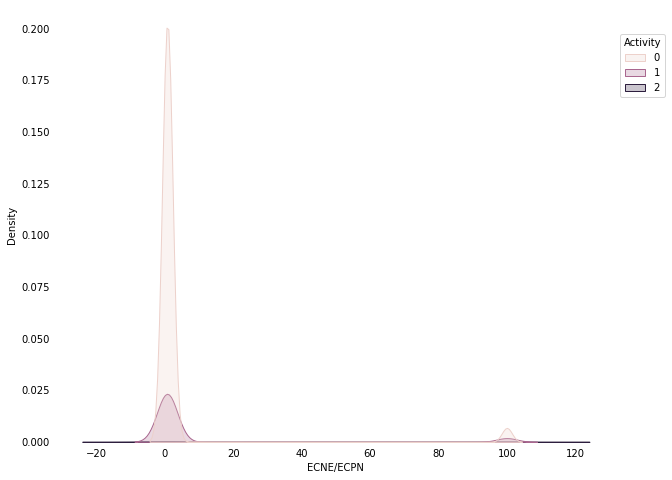

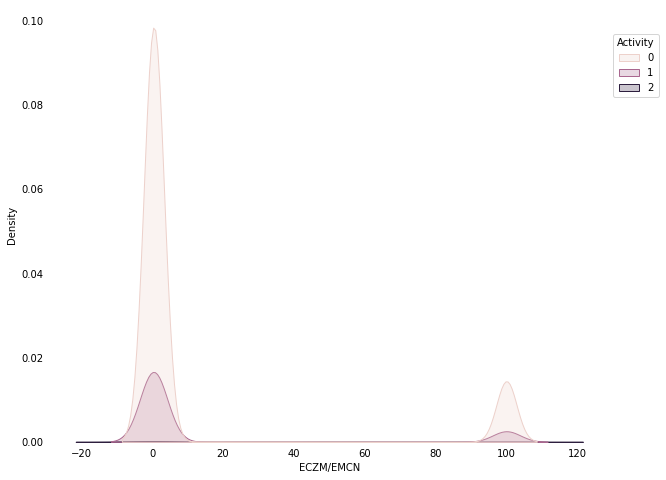

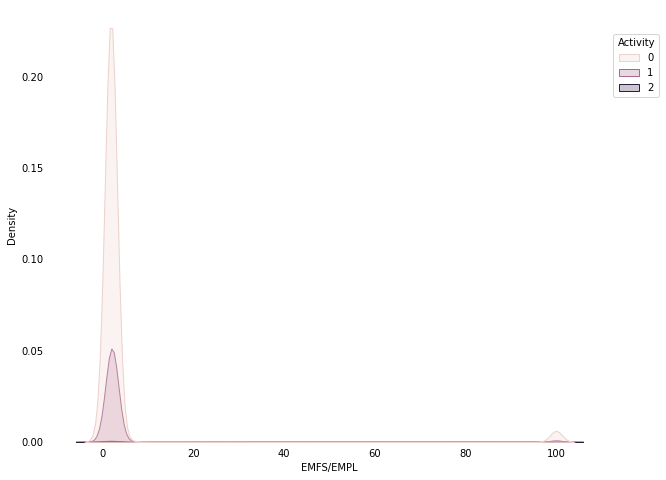

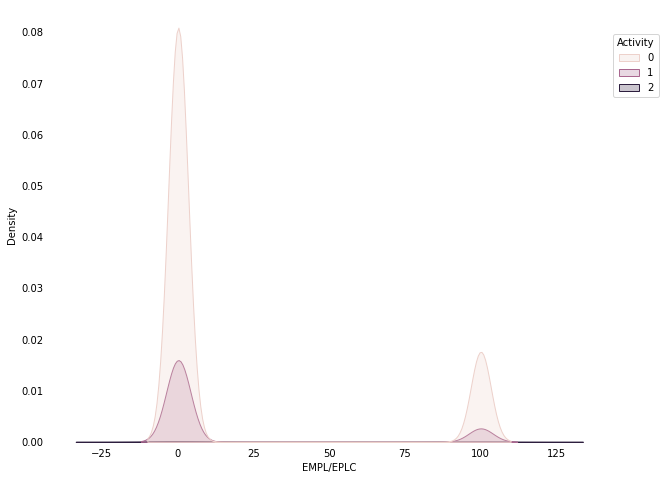

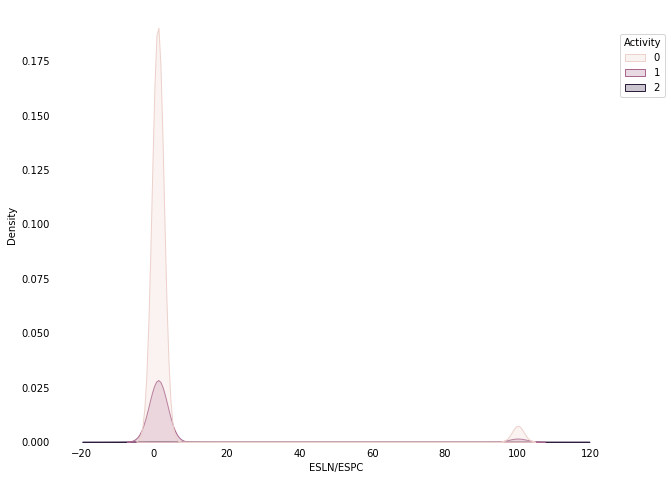

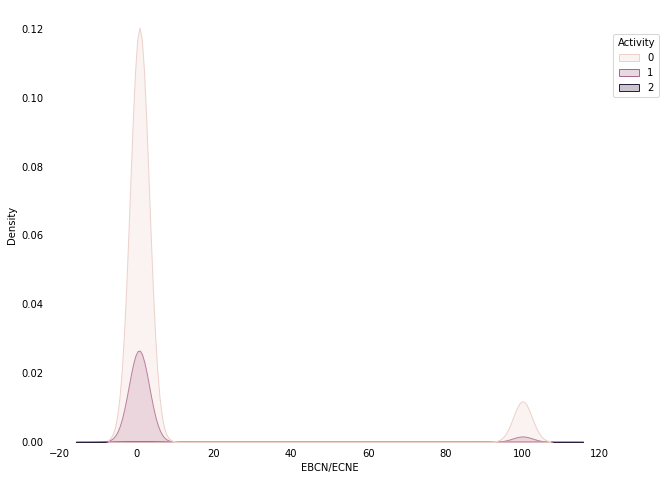

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns


for i in range(1,len(col_names)):
  plt.figure(figsize=(10,8))
  ax=sns.kdeplot(data_ready[col_names[i]],
                hue=data_ready[col_names[0]],
                fill=True)
  sns.despine(top=True, right=True, bottom=True, left=True)
  plt.tick_params(axis='both', which='both', bottom=False, top=False, left=False)
  ax.legend_.set_bbox_to_anchor((1, 0.95))
  ax.legend_._set_loc(2)
  #plt.savefig("im_kde"+str(i)+".png",dpi=300)
  plt.show()

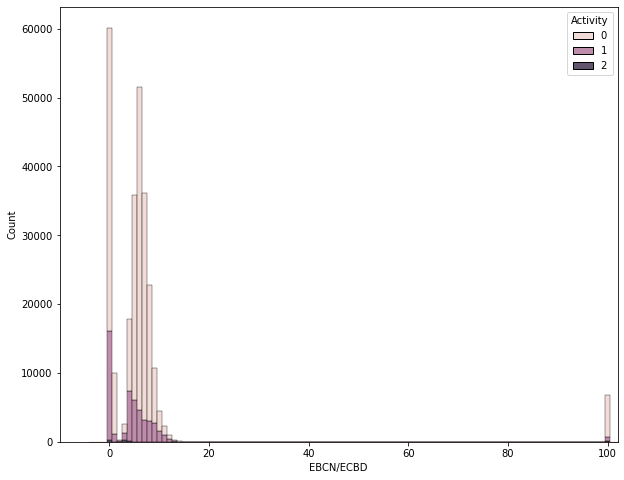

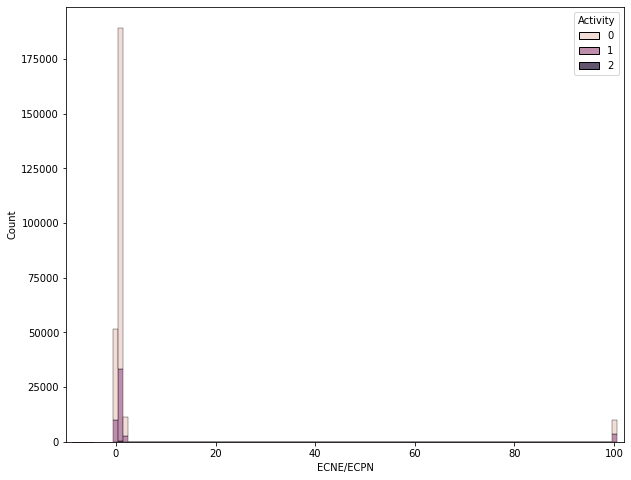

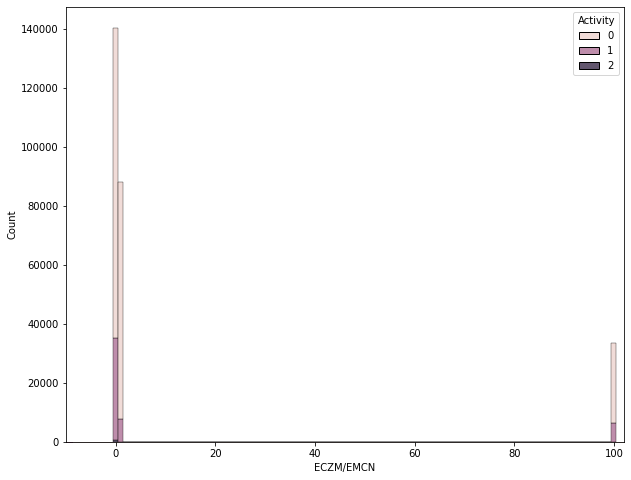

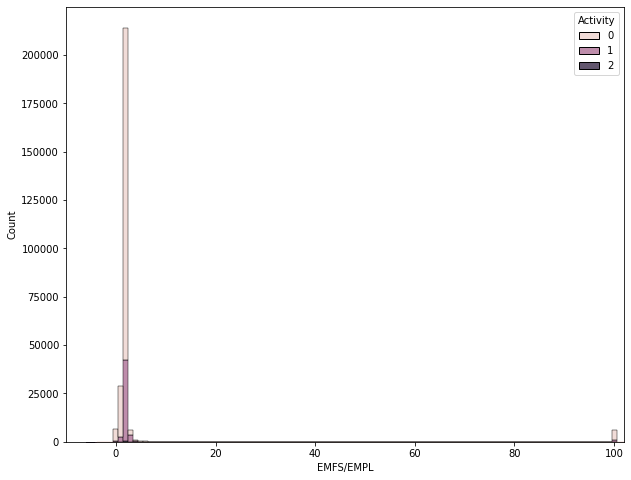

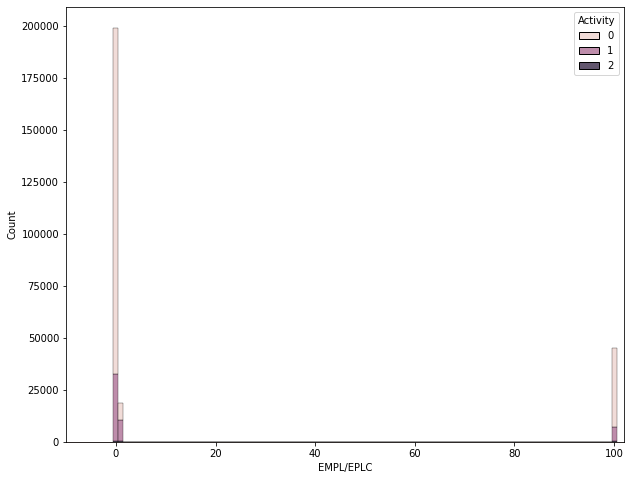

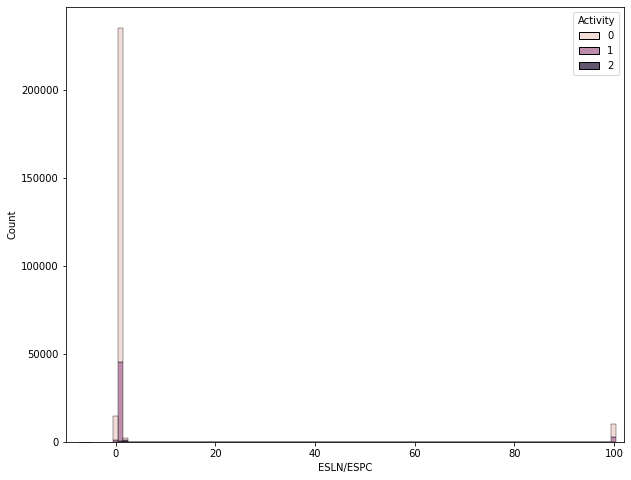

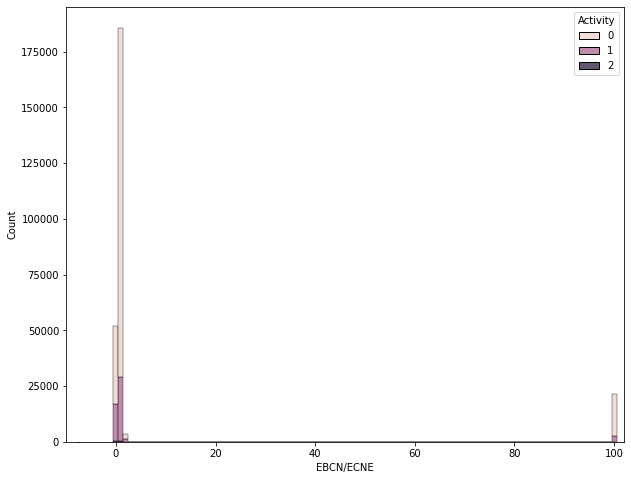

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

for i in range(1,len(col_names)):
  plt.figure(figsize=(10,8))
  ax=sns.kdeplot(data_ready[col_names[i]],
                hue=data_ready[col_names[0]],
                fill=True)
  
  sns.histplot(data=data_ready, x=col_names[i], discrete=True,multiple='stack',
               ax=ax,hue=col_names[0])
  plt.ylabel('Count')
  plt.xlim([np.min(data_ready[col_names[i]])-10,102])
  plt.show()

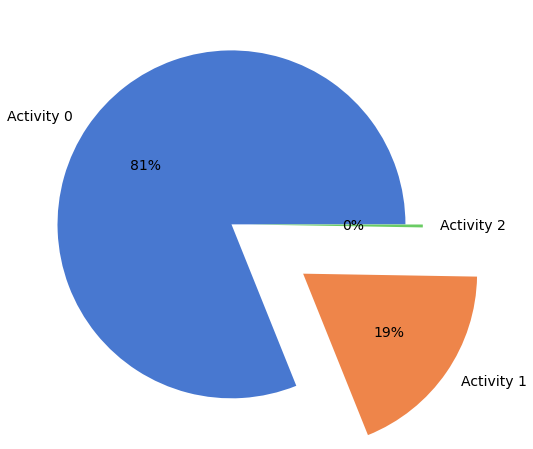

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
col_names=data_ready.columns
data_act=data_ready.groupby(["Activity"]).count()[["EBCN/ECBD"]]
lst_act=data_act.index.astype(int).astype(str).tolist()
lst_act=[ "Activity "+ item for item in lst_act]


plt.figure(figsize=(8,8))
palette_color = sns.color_palette('muted')

plt.pie(data_act["EBCN/ECBD"].values,
        labels=lst_act,explode=[0 ,0.5,0.1],
        colors=palette_color, autopct='%.0f%%',textprops={'fontsize': 14})
#plt.savefig("im_pie.png",dpi=300)
plt.show()

# **Normalization**

Text(0.5, 1.0, ' processing data range')

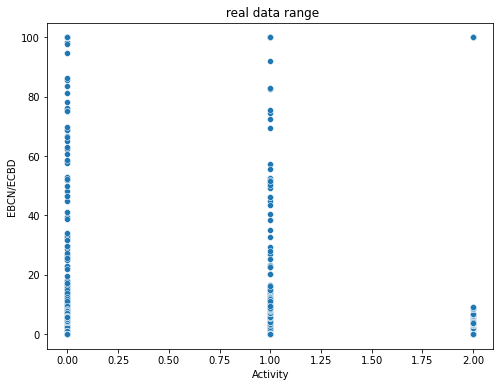

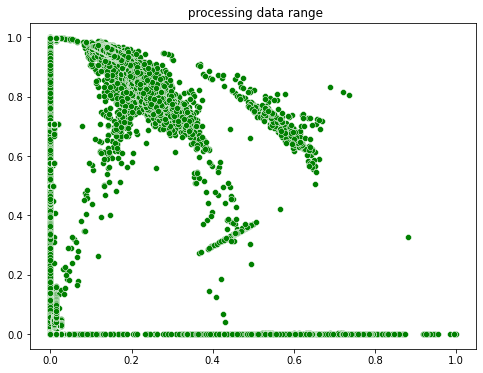

In [27]:
from sklearn.preprocessing import Normalizer, MinMaxScaler
from sklearn.pipeline import Pipeline
import seaborn as sns
import matplotlib.pyplot as plt
# create pipline
pipeline = Pipeline([('Normalizer', Normalizer()),
                     ('MinMaxScaler', MinMaxScaler())])
# fit and transform
data_normal = pipeline.fit_transform(data_ready)

# plot un process data
plt.figure(figsize=(8,6))
sns.scatterplot(x=data_ready.iloc[:,0],
                y=data_ready.iloc[:,1])
plt.title(" real data range")
plt.savefig("im_rel.png",dpi=300)
# plot processing data
plt.figure(figsize=(8,6))
sns.scatterplot(x=data_normal[:,0],
                y=data_normal[:,1],
                color="green")
plt.title(" processing data range")
#plt.savefig("im_proc.png",dpi=300)

Text(0.5, 1.0, ' Normalization data range')

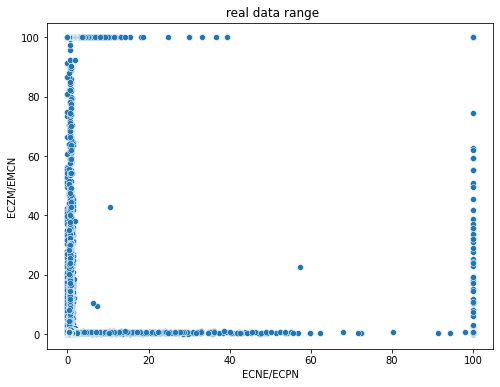

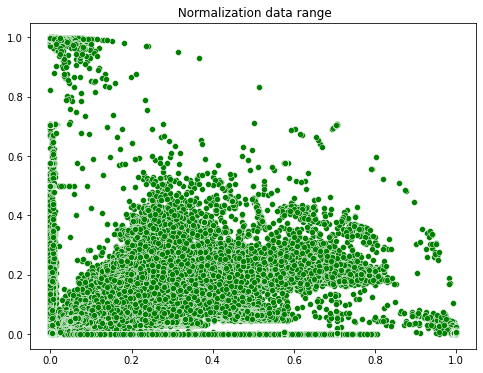

In [28]:
# plot un process data
plt.figure(figsize=(8,6))
sns.scatterplot(x=data_ready.iloc[:,2],
                y=data_ready.iloc[:,3])
plt.title(" real data range")
#plt.savefig("Pre_Norm.png",dpi=300)

# plot processing data
plt.figure(figsize=(8,6))
sns.scatterplot(x=data_normal[:,2],
                y=data_normal[:,3],
                color="green")
plt.title(" Normalization data range")
#plt.savefig("Norm.png",dpi=300)

# **anomaly detection base seasonal**

In [29]:
columns_label="EBCN/ECNE"
data_ready_sea=pd.DataFrame()
data_ready_sea[columns_label]=data_ready[columns_label]
data_ready_sea["time"]=data_main[data_main.columns[0]]
#data_ready_sea=data_ready_sea.set_index("time")
data_ready_sea=data_ready_sea.drop("time",axis=1)
data_ready_sea

,EBCN/ECNE
date_time (month/day/year/hour/minute),
2011-01-01 00:00:00,0.835803
2011-01-01 00:10:00,0.785281
2011-01-01 00:20:00,0.786350
2011-01-01 00:30:00,0.755097
2011-01-01 00:40:00,0.805580
...,...
2015-12-31 23:10:00,0.000596
2015-12-31 23:20:00,0.000572
2015-12-31 23:30:00,0.000582


<ipython-input-30-29b3d421cea2>:6: FutureWarning: the 'freq'' keyword is deprecated, use 'period' instead
  seasonal_result = seasonal_decompose(data_ready_sea,model='additive',freq=freq_seasonal)


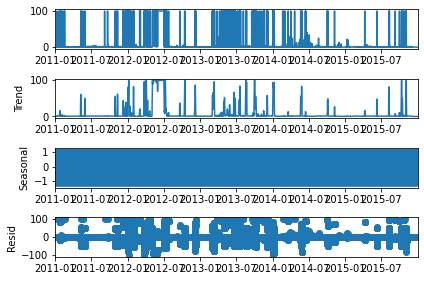

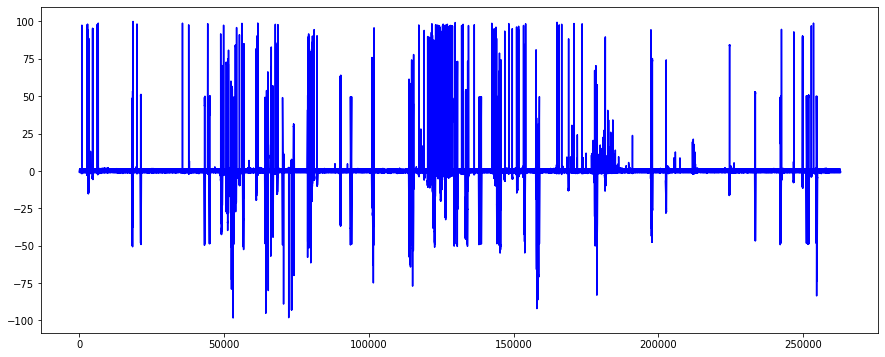

In [30]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.dates as mdates

freq_seasonal=144*2
# get seasonal
seasonal_result = seasonal_decompose(data_ready_sea,model='additive',freq=freq_seasonal)
seasonal_result.plot()
plt.savefig("STL.png",dpi=300)
#
plt.figure(figsize=(15,6))
y = seasonal_result.resid
x = range(len(y) )
plt.plot(x, y, color='blue',linestyle='-')
plt.savefig("Resid.png",dpi=300)

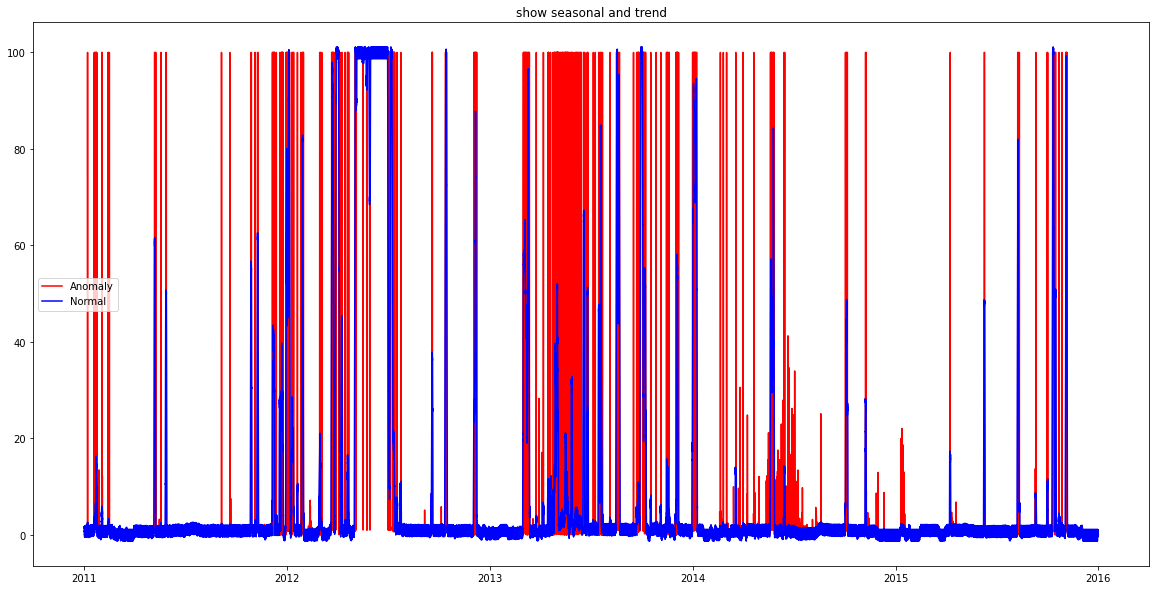

In [31]:
plt.figure(figsize=(20,10))
y=data_ready_sea
x = data_ready_sea.index
plt.plot(data_ready_sea, color='red',linestyle='-',label="Anomaly")
y = seasonal_result.trend+seasonal_result.seasonal
# x = range(len(y) )
plt.plot(data_ready_sea.index, y, color='blue',linestyle='-',label="Normal")
plt.title("show seasonal and trend")
plt.savefig("seasonal and trend.png",dpi=300)
plt.legend()


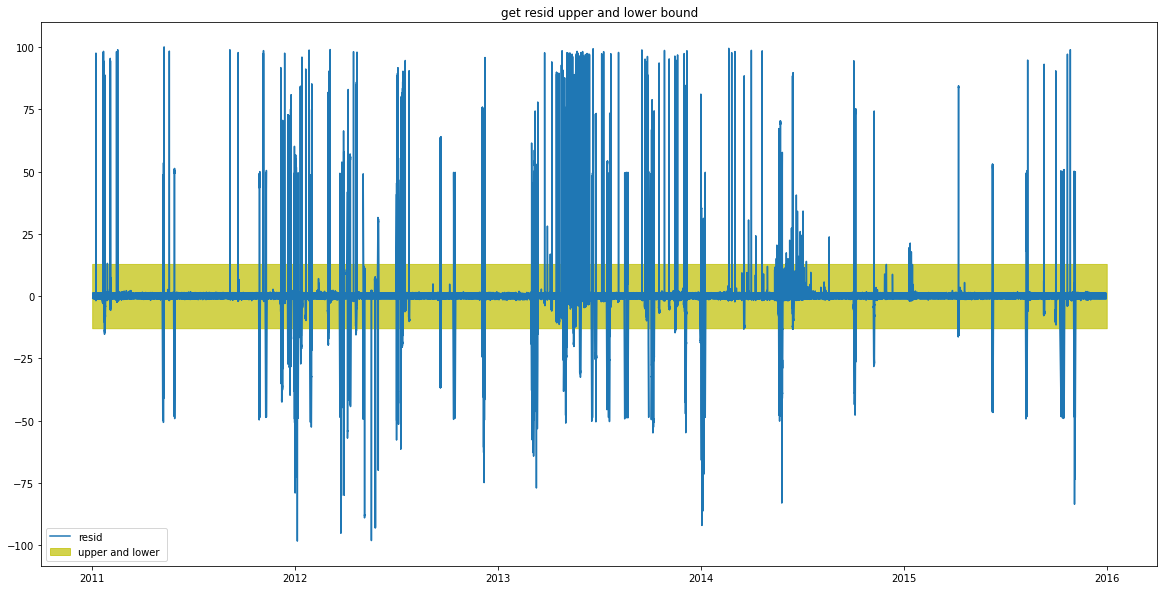

In [94]:
import numpy as np
plt.figure(figsize=(20,10))


resid = seasonal_result.resid.values
weight_resid=(np.nanmax(resid)/(np.nanmax(resid)+0.2))
x = data_ready_sea.index
mean_resid=np.nanmean(resid)
std_resid=np.nanstd(resid)
lb=mean_resid-weight_resid*std_resid
ub=mean_resid+weight_resid*std_resid
plt.plot(x, resid, '-',label="resid")
plt.fill_between(x, lb ,ub, alpha=0.7,color="y",label="upper and lower ")
plt.title("get resid upper and lower bound")
plt.legend()
# plt.savefig("Resid upper and lower.png",dpi=300)

In [98]:
(np.nanmax(resid)+(np.nanmax(resid)//10)/(np.nanmax(resid)))

100.11020627462246

In [33]:
resid=resid.reshape(resid.shape[0])
resid.shape

(262944,)

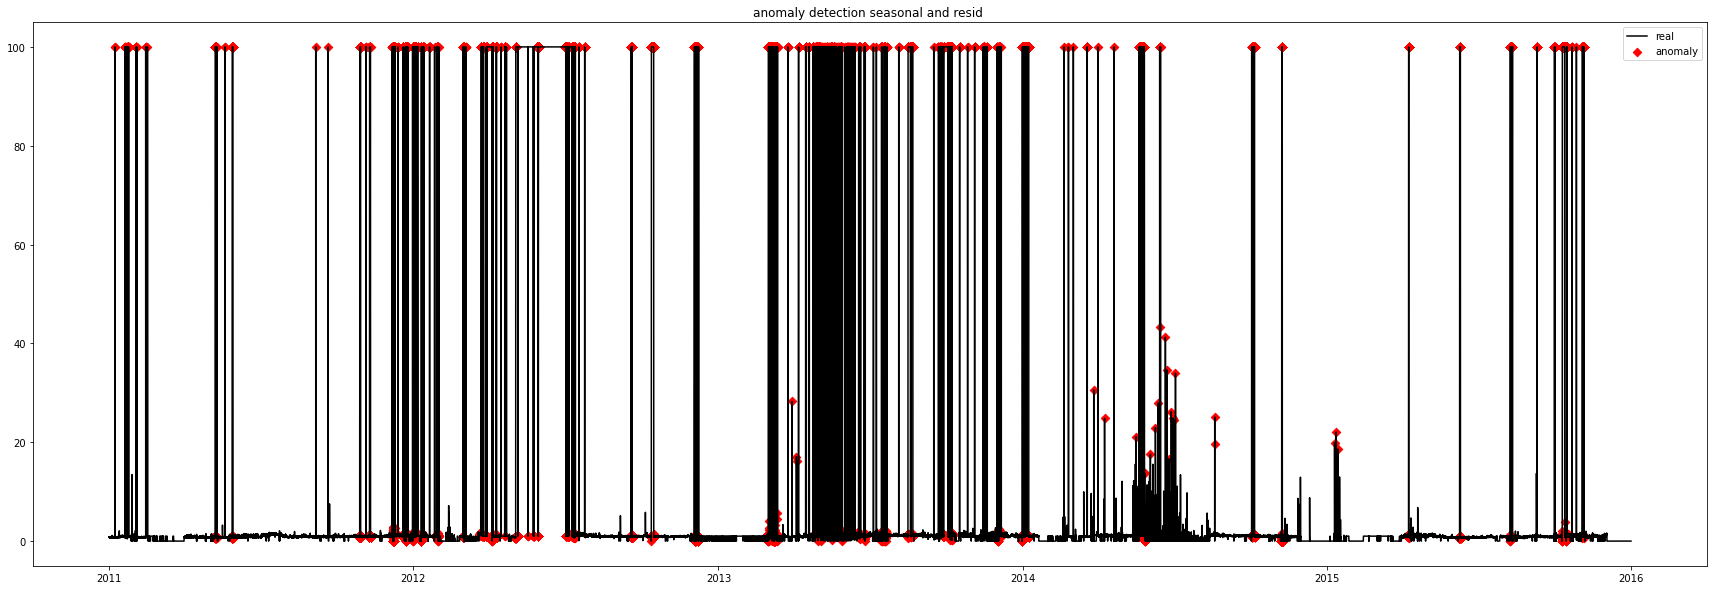

In [34]:
plt.figure(figsize=(30,10))
anomaly = data_ready_sea[(resid < lb) | (resid > ub)]
x = np.array(range(len(data_ready_sea) ))
idx_anomaly=x[(resid < lb) | (resid > ub)]
plt.plot(data_ready_sea,label="real",color='black')
plt.scatter(anomaly.index,anomaly, color='r', marker='D',label="anomaly")
plt.title("anomaly detection seasonal and resid ")
plt.legend()
plt.savefig("Anomaly detection.png",dpi=300)


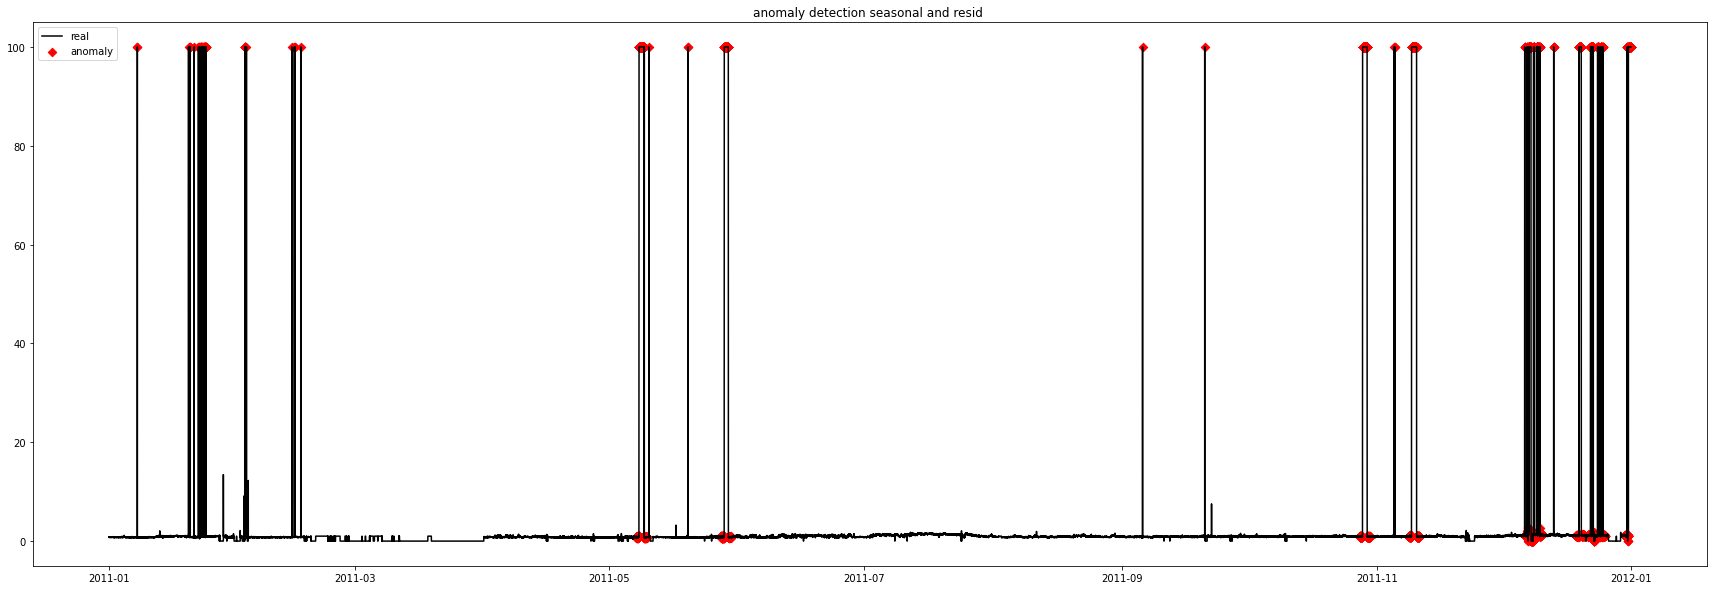

In [35]:
data_date=data_ready_sea.loc[data_ready_sea.index>'2011-1-1']
data_date_ready_sea=data_date.loc[data_date.index<'2012-1-1']

anomaly_date=anomaly.loc[anomaly.index>'2011-1-1']
anomaly_date_date_ready_sea=anomaly_date.loc[anomaly_date.index<'2012-1-1']
plt.figure(figsize=(30,10))
anomaly = data_ready_sea[(resid < lb) | (resid > ub)]
x = np.array(range(len(data_ready_sea) ))
idx_anomaly=x[(resid < lb) | (resid > ub)]
plt.plot(data_date_ready_sea,label="real",color='black')
plt.scatter(anomaly_date_date_ready_sea.index,anomaly_date_date_ready_sea, color='r', marker='D',label="anomaly")
plt.title("anomaly detection seasonal and resid ")
plt.legend()
plt.savefig("Anomaly detection 1year.png",dpi=300)


In [36]:
anomaly

,EBCN/ECNE
date_time (month/day/year/hour/minute),
2011-01-07 18:10:00,100.000000
2011-01-07 18:20:00,100.000000
2011-01-20 01:00:00,100.000000
2011-01-20 08:10:00,100.000000
2011-01-20 08:20:00,100.000000
...,...
2015-11-06 01:50:00,0.888655
2015-11-06 02:00:00,0.827038
2015-11-06 02:10:00,0.719892


In [37]:
anomaly_date_date_ready_sea.to_csv("ano.csv")

In [38]:
data_normal_new=data_normal[:,1:]

In [39]:
data_normal_new.shape

(262944, 7)

# **window on data**

In [40]:
import numpy as np
from tqdm import tqdm
def multivariate_data(dataset, target, history_size,
                      target_size, step, single_step=False):
    data = []
    labels = []
    start_index=0
    end_index = None
    start_index = start_index + history_size
    if end_index is None:
        end_index = len(dataset) - target_size

    for i in tqdm(range(start_index, end_index)):
        indices = range(i-history_size, i, step)
        data.append(dataset[indices])

        if single_step:
            labels.append(target[i+target_size])
        else:
            labels.append(target[i:i+target_size])

    return np.array(data), np.array(labels)

In [41]:
from tqdm import tqdm
past_history = 4
STEP = 1
n_step=1
index_Close = -1
col_idx=[0,1,2,3,4,5,6]
#col_idx=[index_Close]
data_can, lbl_reg= multivariate_data(data_normal[:,col_idx], 
                                     data_normal[:,index_Close],
                                     past_history,
                                     n_step, STEP,
                                     single_step=True)

print("_"*50)
print('-> data_can  shape = {0}'.format(data_can.shape))
print('-> lbl_reg   shape = {0}'.format(lbl_reg.shape))
print("_"*50)

100%|██████████| 262939/262939 [00:01<00:00, 159887.85it/s]


__________________________________________________
-> data_can  shape = (262939, 4, 7)
-> lbl_reg   shape = (262939,)
__________________________________________________


# **train and test split**

In [42]:
from sklearn.model_selection import train_test_split
# train split mode
split_type=0;
trian_Percentage=0.85;
if(split_type==1):
  # random
  x_train, x_test, lbl_train, lbl_test=train_test_split(data_can, 
                                                        lbl_reg,
                                                        test_size=1-trian_Percentage,)
  
else:
  # sequence
  idx=round(data_can.shape[0]*trian_Percentage)
  x_train=data_can[0:idx,:]
  x_test=data_can[idx:,:]
  lbl_train=lbl_reg[0:idx].astype(float)
  lbl_test=lbl_reg[idx:].astype(float)


idx_vali=np.int64(x_train.shape[0]*0.82)
x_vali=x_train[idx_vali:]
lbl_vali=lbl_train[idx_vali:]
x_train=x_train[:idx_vali]
lbl_train=lbl_train[:idx_vali]

print("-"*50)
print("train shape: {0} ==> {1}".format(x_train.shape,np.round(x_train.shape[0]/data_can.shape[0],2)))
print("test shape: {0}  ==> {1}".format(x_test.shape,np.round(x_test.shape[0]/data_can.shape[0],2)))
print("vali shape: {0}  ==> {1}".format(x_vali.shape,np.round(x_vali.shape[0]/data_can.shape[0],2)))
print("-"*50)


--------------------------------------------------
train shape: (183268, 4, 7) ==> 0.7
test shape: (39441, 4, 7)  ==> 0.15
vali shape: (40230, 4, 7)  ==> 0.15
--------------------------------------------------


# **LSTM**

In [43]:
epoch_value=50

In [44]:
from tensorflow import keras
from keras.regularizers import l2
def Create_LSTM(data):
  model_LSTM_reg = keras.models.Sequential()
  model_LSTM_reg.add(keras.layers.LSTM(32, input_shape=(data.shape[1],data.shape[2]),
                                                         return_sequences=True,name="lstm_layer1"))
  model_LSTM_reg.add(keras.layers.LSTM(16,activation="relu",name="lstm_layer2",return_sequences=True))
  model_LSTM_reg.add(keras.layers.LSTM(16,activation="relu",name="lstm_layer3"))
  model_LSTM_reg.add(keras.layers.BatchNormalization())
  model_LSTM_reg.add(keras.layers.Dropout(0.1,name="drop1"))
  model_LSTM_reg.add(keras.layers.Dense(256,activation="relu"))
  model_LSTM_reg.add(keras.layers.Dense(n_step))
  model_LSTM_reg.compile(optimizer="Adam",loss="mse")
  return model_LSTM_reg
model_LSTM=Create_LSTM(x_train)
model_LSTM.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_layer1 (LSTM)          (None, 4, 32)             5120      
                                                                 
 lstm_layer2 (LSTM)          (None, 4, 16)             3136      
                                                                 
 lstm_layer3 (LSTM)          (None, 16)                2112      
                                                                 
 batch_normalization (BatchN  (None, 16)               64        
 ormalization)                                                   
                                                                 
 drop1 (Dropout)             (None, 16)                0         
                                                                 
 dense (Dense)               (None, 256)               4352      
                                                        

In [45]:
hist_model_lstm=model_LSTM.fit(x_train,
                                 lbl_train,epochs=epoch_value
                                 ,batch_size=512,
                                 validation_data=(x_vali,lbl_vali))

Epoch 1/50
358/358 [==============================] - 20s 31ms/step - loss: 0.0130 - val_loss: 0.0104
Epoch 2/50
358/358 [==============================] - 7s 21ms/step - loss: 0.0079 - val_loss: 0.0073
Epoch 3/50
358/358 [==============================] - 7s 21ms/step - loss: 0.0074 - val_loss: 0.0071
Epoch 4/50
358/358 [==============================] - 7s 21ms/step - loss: 0.0070 - val_loss: 0.0046
Epoch 5/50
358/358 [==============================] - 7s 20ms/step - loss: 0.0069 - val_loss: 0.0047
Epoch 6/50
358/358 [==============================] - 7s 20ms/step - loss: 0.0067 - val_loss: 0.0051
Epoch 7/50
358/358 [==============================] - 7s 20ms/step - loss: 0.0065 - val_loss: 0.0058
Epoch 8/50
358/358 [==============================] - 7s 20ms/step - loss: 0.0064 - val_loss: 0.0045
Epoch 9/50
358/358 [==============================] - 7s 20ms/step - loss: 0.0063 - val_loss: 0.0060
Epoch 10/50
358/358 [==============================] - 7s 20ms/step - loss: 0.0062 - val_l

In [46]:
# from matplotlib import pyplot as plt
# plt.figure(figsize=(10,8))
# loss_lstm=hist_model_lstm.history['loss']
# val_loss_lstm=hist_model_lstm.history['val_loss']
# plt.plot(loss_lstm,label="loss")
# plt.plot(val_loss_lstm,label="val_loss")
# plt.legend()
# plt.title("loss on train and test")
# plt.ylabel("loss(MSE)")
# plt.show()

# **CNNLSTM**

In [48]:
x_test_re=x_test.reshape(x_test.shape[0],
                         x_test.shape[1],
                         x_test.shape[2],1
                         )
x_vali_re=x_vali.reshape(x_vali.shape[0],
                         x_vali.shape[1],
                         x_vali.shape[2],1
                         )

x_train_re=x_train.reshape(x_train.shape[0],
                         x_train.shape[1],
                         x_train.shape[2],1
                         )


In [62]:
from keras.backend import reshape
from tensorflow import keras
def Create_CNN_LSTM(data):
  input_layer=keras.layers.Input(shape=(data.shape[1],data.shape[2]),name="input_layer")
  model=keras.models.Sequential([input_layer,
                                 keras.layers.Conv1D(filters=32,
                                                    kernel_size=(2),
                                                    activation="relu",
                                                    strides=(1),
                                                    padding="same",
                                                    name="conv1"),
                                 keras.layers.Conv1D(filters=16,
                                                    kernel_size=(2),
                                                    activation="relu",
                                                    strides=(1),
                                                    padding="same",
                                                    name="conv2"),
                                keras.layers.MaxPool1D(pool_size=(2),name="maxpool1"),
                                keras.layers.LSTM(128,activation="relu"),
                                keras.layers.Flatten(),
                                keras.layers.Dropout(0.5),
                                keras.layers.Dense(200, activation="relu"),
                                keras.layers.Dense(n_step,
                                                   activation="linear",
                                                   name="out_layer")
                                
                                ]
                                
                                )
  model.compile(optimizer="Adam",loss="mse")
  return model
model_cnn_lstm=Create_CNN_LSTM(x_train)
model_cnn_lstm.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1 (Conv1D)              (None, 4, 32)             480       
                                                                 
 conv2 (Conv1D)              (None, 4, 16)             1040      
                                                                 
 maxpool1 (MaxPooling1D)     (None, 2, 16)             0         
                                                                 
 lstm_2 (LSTM)               (None, 128)               74240     
                                                                 
 flatten_2 (Flatten)         (None, 128)               0         
                                                                 
 dropout_2 (Dropout)         (None, 128)               0         
                                                                 
 dense_4 (Dense)             (None, 200)              

In [63]:
model_CNNLSTM=Create_CNN_LSTM(x_train_re)
hist_model_cnnlstm=model_CNNLSTM.fit(x_train,
                                      lbl_train,epochs=epoch_value
                                    ,batch_size=512,
                                    validation_data=(x_vali_re,lbl_vali))

Epoch 1/50
358/358 [==============================] - 5s 10ms/step - loss: 0.0152 - val_loss: 0.0047
Epoch 2/50
358/358 [==============================] - 3s 9ms/step - loss: 0.0067 - val_loss: 0.0042
Epoch 3/50
358/358 [==============================] - 3s 9ms/step - loss: 0.0063 - val_loss: 0.0042
Epoch 4/50
358/358 [==============================] - 3s 9ms/step - loss: 0.0061 - val_loss: 0.0045
Epoch 5/50
358/358 [==============================] - 3s 9ms/step - loss: 0.0060 - val_loss: 0.0040
Epoch 6/50
358/358 [==============================] - 3s 9ms/step - loss: 0.0060 - val_loss: 0.0042
Epoch 7/50
358/358 [==============================] - 3s 9ms/step - loss: 0.0059 - val_loss: 0.0047
Epoch 8/50
358/358 [==============================] - 3s 9ms/step - loss: 0.0059 - val_loss: 0.0045
Epoch 9/50
358/358 [==============================] - 3s 9ms/step - loss: 0.0059 - val_loss: 0.0045
Epoch 10/50
358/358 [==============================] - 3s 9ms/step - loss: 0.0059 - val_loss: 0.004

In [83]:
# from matplotlib import pyplot as plt
# plt.figure(figsize=(10,8))
# loss_lstm=hist_model_cnnlstm.history['loss']
# val_loss_lstm=hist_model_cnnlstm.history['val_loss']
# plt.plot(loss_lstm,label="loss")
# plt.plot(val_loss_lstm,label="val_loss")
# plt.legend()
# plt.title("loss on train and test")
# plt.ylabel("loss(MSE)")
# plt.show()

# **Result of all Metrics**

In [64]:
all_model=[model_LSTM,model_CNNLSTM]

In [65]:

algorithm_name=["LSTM","CNNLSTM"]
metrics_name=["MSE","RMSE","MAE","R2"]
result_array=np.zeros((len(algorithm_name),len(metrics_name)+1))
columns_name=metrics_name
columns_name.insert(0,"algorithm_name")
res_metrics_all=pd.DataFrame(result_array,columns=columns_name)
res_metrics_all["algorithm_name"]=algorithm_name
res_metrics_all

,algorithm_name,MSE,RMSE,MAE,R2
0,LSTM,0.0,0.0,0.0,0.0
1,CNNLSTM,0.0,0.0,0.0,0.0


In [66]:
from sklearn import metrics
import math

for k, model in enumerate(all_model):
  print("Load model: "+ algorithm_name[k])
  lbl_pred=model.predict(x_test)
  lbl_real=lbl_test
  #============================================================================
  mse=metrics.mean_squared_error(lbl_real, lbl_pred)
  rmse = math.sqrt(mse)
  mae=metrics.mean_absolute_error(lbl_real,lbl_pred)
  r2= metrics.r2_score(lbl_real, lbl_pred)

  result_array[k,1]=mse
  result_array[k,2]=rmse
  result_array[k,3]=mae
  result_array[k,4]=r2


Load model: LSTM
1233/1233 [==============================] - 4s 3ms/step
Load model: CNNLSTM
1233/1233 [==============================] - 3s 2ms/step


In [67]:
res_metrics_all=pd.DataFrame(result_array,columns=columns_name)
res_metrics_all["algorithm_name"]=algorithm_name
res_metrics_all


,algorithm_name,MSE,RMSE,MAE,R2
0,LSTM,0.002605,0.051042,0.034831,0.786049
1,CNNLSTM,0.002708,0.052043,0.034526,0.777574


<Figure size 720x720 with 0 Axes>

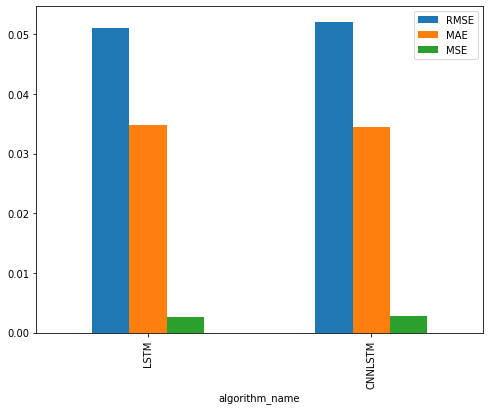

In [68]:
import matplotlib.pyplot as plt
fig=plt.figure(figsize=(10,10))
res_metrics_all.plot(x="algorithm_name",
                     y=["RMSE","MAE","MSE"],
                     kind="bar",figsize=(8,6)).legend(loc='best')
plt.xlim([-.5,1.5])
plt.savefig("RMSE,MAE,MSE.png",dpi=300)

<Figure size 720x720 with 0 Axes>

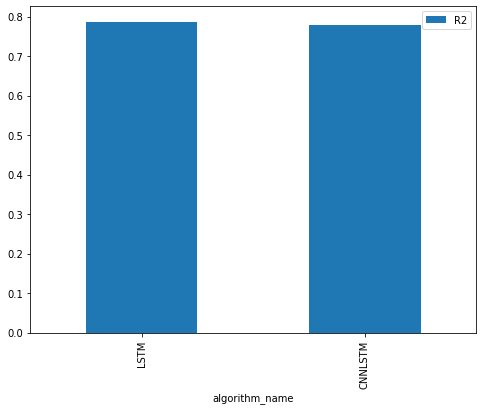

In [69]:
import matplotlib.pyplot as plt
fig=plt.figure(figsize=(10,10))
res_metrics_all.plot(x="algorithm_name",
                     y=["R2"],
                     kind="bar",figsize=(8,6)).legend(loc='best')
plt.xlim([-.5,1.5])
plt.savefig("R2.png",dpi=300)


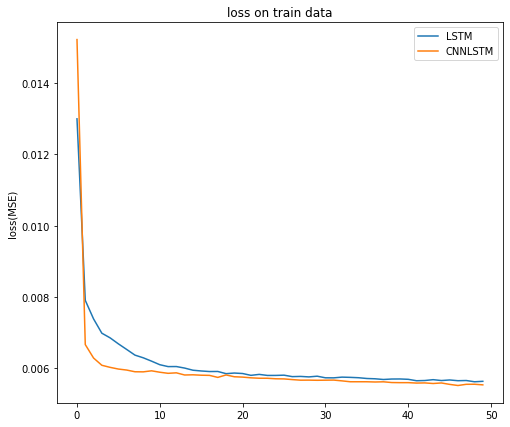

In [70]:
from matplotlib import pyplot as plt
plt.figure(figsize=(8,7))
loss_lstm=hist_model_lstm.history['loss']
loss_cnnlstm=hist_model_cnnlstm.history['loss']
plt.plot(loss_lstm,label="LSTM")
plt.plot(loss_cnnlstm,label="CNNLSTM")
plt.legend()
plt.title("loss on train data")
plt.ylabel("loss(MSE)")
plt.savefig("loss on train data.png",dpi=300)
plt.show()



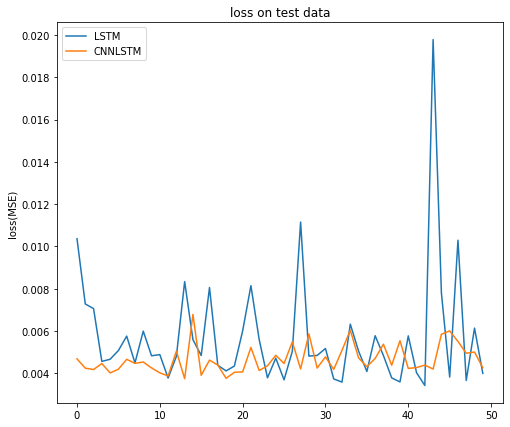

In [71]:
from matplotlib import pyplot as plt
plt.figure(figsize=(8,7))
loss_lstm=hist_model_lstm.history['val_loss']
loss_cnnlstm=hist_model_cnnlstm.history['val_loss']
plt.plot(loss_lstm,label="LSTM")
plt.plot(loss_cnnlstm,label="CNNLSTM")
plt.legend()
plt.title("loss on test data")
plt.ylabel("loss(MSE)")
plt.savefig("loss on test data.png",dpi=300)
plt.show()

1233/1233 [==============================] - 5s 4ms/step


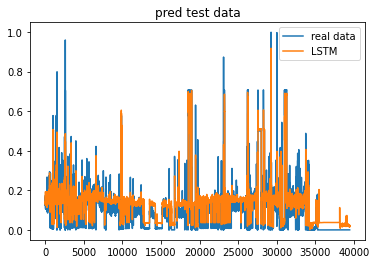

In [72]:

pred_lstm=model_LSTM.predict(x_test)
plt.plot(lbl_test,label="real data")
plt.plot(pred_lstm,label="LSTM")
plt.title("pred test data")
plt.legend()
plt.xlabel("")
plt.ylabel("")
plt.savefig("pred test LSTM.png",dpi=300)
plt.show()

1233/1233 [==============================] - 3s 3ms/step


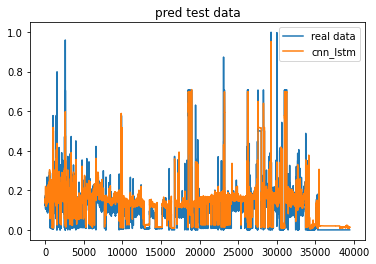

In [74]:
pred_cnn_lstm=model_CNNLSTM.predict(x_test)
plt.plot(lbl_test,label="real data")
plt.plot(pred_cnn_lstm,label="cnn_lstm")
plt.title("pred test data")
plt.xlabel("")
plt.ylabel("")
plt.legend()
plt.savefig("pred test CNNLSTM.png",dpi=300)
plt.show()

## **vali**

In [75]:
all_model=[model_LSTM,model_CNNLSTM]

In [76]:

algorithm_name=["LSTM","CNNLSTM"]
metrics_name=["MSE","RMSE","MAE","R2"]
result_array=np.zeros((len(algorithm_name),len(metrics_name)+1))
columns_name=metrics_name
columns_name.insert(0,"algorithm_name")
res_metrics_all=pd.DataFrame(result_array,columns=columns_name)
res_metrics_all["algorithm_name"]=algorithm_name
res_metrics_all

,algorithm_name,MSE,RMSE,MAE,R2
0,LSTM,0.0,0.0,0.0,0.0
1,CNNLSTM,0.0,0.0,0.0,0.0


In [77]:
from sklearn import metrics
import math

for k, model in enumerate(all_model):
  print("Load model: "+ algorithm_name[k])
  lbl_pred=model.predict(x_vali)
  lbl_real=lbl_vali
  #============================================================================
  mse=metrics.mean_squared_error(lbl_real, lbl_pred)
  rmse = math.sqrt(mse)
  mae=metrics.mean_absolute_error(lbl_real,lbl_pred)
  r2= metrics.r2_score(lbl_real, lbl_pred)

  result_array[k,1]=mse
  result_array[k,2]=rmse
  result_array[k,3]=mae
  result_array[k,4]=r2


Load model: LSTM
1258/1258 [==============================] - 5s 4ms/step
Load model: CNNLSTM
1258/1258 [==============================] - 3s 2ms/step


In [78]:
res_metrics_all=pd.DataFrame(result_array,columns=columns_name)
res_metrics_all["algorithm_name"]=algorithm_name
res_metrics_all


,algorithm_name,MSE,RMSE,MAE,R2
0,LSTM,0.003995,0.063208,0.034562,0.643129
1,CNNLSTM,0.004261,0.065280,0.034456,0.619351


<Figure size 720x720 with 0 Axes>

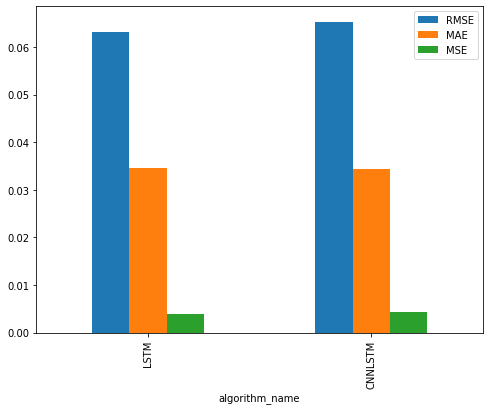

In [79]:
import matplotlib.pyplot as plt
fig=plt.figure(figsize=(10,10))
res_metrics_all.plot(x="algorithm_name",
                     y=["RMSE","MAE","MSE"],
                     kind="bar",figsize=(8,6)).legend(loc='best')
plt.xlim([-.5,1.5])
plt.savefig("RMSE,MAE,MSE.png",dpi=300)

<Figure size 720x720 with 0 Axes>

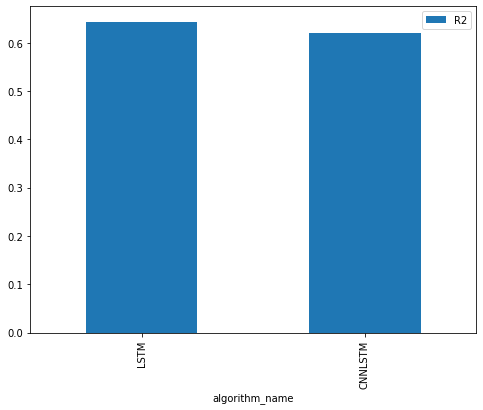

In [80]:
import matplotlib.pyplot as plt
fig=plt.figure(figsize=(10,10))
res_metrics_all.plot(x="algorithm_name",
                     y=["R2"],
                     kind="bar",figsize=(8,6)).legend(loc='best')
plt.xlim([-.5,1.5])
plt.savefig("R2.png",dpi=300)


1258/1258 [==============================] - 5s 3ms/step


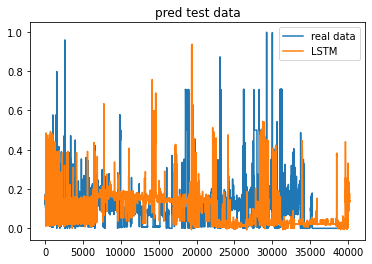

In [81]:

pred_lstm=model_LSTM.predict(x_vali)
plt.plot(lbl_test,label="real data")
plt.plot(pred_lstm,label="LSTM")
plt.title("pred test data")
plt.legend()
plt.xlabel("")
plt.ylabel("")
plt.savefig("pred test LSTM.png",dpi=300)
plt.show()

1258/1258 [==============================] - 3s 2ms/step


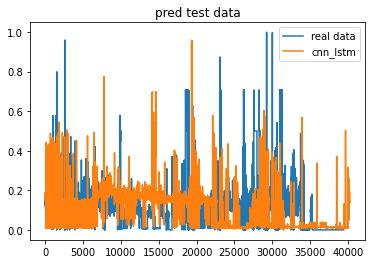

In [82]:
pred_cnn_lstm=model_CNNLSTM.predict(x_vali)
plt.plot(lbl_test,label="real data")
plt.plot(pred_cnn_lstm,label="cnn_lstm")
plt.title("pred test data")
plt.xlabel("")
plt.ylabel("")
plt.legend()
plt.savefig("pred test CNNLSTM.png",dpi=300)
plt.show()

4/4 [==============================] - 0s 11ms/step


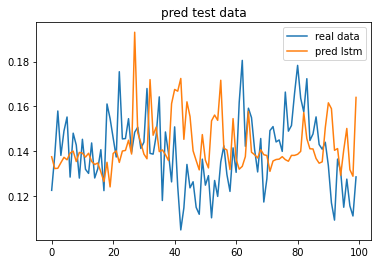

In [92]:
idx=100
pred_lstm=model_LSTM.predict(x_test[0:idx])
plt.plot(lbl_test[0:idx],label="real data")
plt.plot(pred_lstm,label="pred lstm")
plt.title("pred test data")
plt.xlabel("")
plt.ylabel("")
plt.legend()
plt.savefig("pred test CNNLSTM.png",dpi=300)
plt.show()